# Домашнее задание №4. Логистическая регрессия. Оптимизация. Подбор гиперпараметров

## Ф.И.О: Чайкин Владимир Денисович

По вопросам в задании писать в беседу курса или в лс (tg: @Skorik_S)

## Задание 1: Теоретическая часть

Постановка задачи логистической регрессии:
$$
    \mathcal{L}(\theta, X, y) = \dfrac{1}{N}\sum_{i=1}^N\log(1 + e^{-y_i\langle\theta, x_i\rangle}) → \min_{θ \in \mathbb{R}^d}, \tag{1}
$$

в которой


1.   $θ \in \mathbb{R}^d$ - вектор параметров модели.
2.   $(x_i, y_i)$ - обучающая пара. В данной постановке $y = \{-1, 1\}$.



### Задача 0 (0.5 балла)

1. *Получите постановку логистической регрессии, используя принцип максимума правдоподобия в предположении $y = \{0, 1\}$.*
2. Проверьте, что если метки классов $y = \{-1, 1\}$, то полученная постановка примет вид (1).
---

1. Пусть $y_i \in \{0, 1\}$ и модель предсказывает вероятность:
$$P(y_i = 1 | x_i, \theta) = \sigma(\theta^T x_i) = \frac{1}{1 + e^{-\theta^T x_i}}$$
$$P(y_i = 0 | x_i, \theta) = 1 - \sigma(\theta^T x_i) = \frac{1}{1 + e^{\theta^T x_i}}$$

Тогда
$$P(y_i | x_i, \theta) = \sigma(\theta^T x_i)^{y_i} \cdot (1 - \sigma(\theta^T x_i))^{1 - y_i}$$

Функция правдоподобия:
$$L(\theta) = \prod_{i=1}^N P(y_i | x_i, \theta) = \prod_{i=1}^N \sigma(\theta^T x_i)^{y_i} \cdot (1 - \sigma(\theta^T x_i))^{1 - y_i}$$

Логарифмическая функция правдоподобия:
$$\log L(\theta) = \sum_{i=1}^N \left[ y_i \log \sigma(\theta^T x_i) + (1 - y_i) \log (1 - \sigma(\theta^T x_i)) \right]$$

Используя свойство $\sigma(-z) = 1 - \sigma(z)$, получаем:
$$\log L(\theta) = \sum_{i=1}^N \left[ y_i \log \sigma(\theta^T x_i) + (1 - y_i) \log \sigma(-\theta^T x_i) \right]$$

$$\mathcal{L}(\theta) = -\frac{1}{N} \log L(\theta) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log \sigma(\theta^T x_i) + (1 - y_i) \log \sigma(-\theta^T x_i) \right]$$

2. Пусть теперь $y_i \in \{-1, 1\}$. Заметим, что:
- Если $y_i = 1$: $P(y_i = 1 | x_i, \theta) = \sigma(\theta^T x_i)$
- Если $y_i = -1$: $P(y_i = -1 | x_i, \theta) = \sigma(-\theta^T x_i)$

$$P(y_i | x_i, \theta) = \sigma(y_i \cdot \theta^T x_i) = \frac{1}{1 + e^{-y_i \theta^T x_i}}$$

Функция правдоподобия:
$$L(\theta) = \prod_{i=1}^N \frac{1}{1 + e^{-y_i \theta^T x_i}}$$

Логарифмическая функция правдоподобия:
$$\log L(\theta) = -\sum_{i=1}^N \log(1 + e^{-y_i \theta^T x_i})$$

$$\mathcal{L}(\theta) = -\frac{1}{N} \log L(\theta) = \frac{1}{N} \sum_{i=1}^N \log(1 + e^{-y_i \theta^T x_i})$$

Что в точности соответствует (1).

### Задача 1* (2 балла)

1. Покажите, что градиент функции потерь равен:

$$\nabla \mathcal{L}(\theta, X, y) = - \dfrac{1}{N}\sum_{i=1}^N \dfrac{y_i x_{i}e^{-y_i\langle\theta, x_i\rangle}}{1 + e^{-y_i\langle\theta, x_i\rangle}}. $$

2. Покажите, что гессиан функции потерь равен:

$$ \nabla^2 \mathcal{L}(\theta, X, y) = \dfrac{1}{N}X^\top D X, \tag{2}$$
где $D$ - диагональная матрица с элементами $\sigma(-y_i\langle\theta, x_i\rangle)(1 - \sigma(-y_i\langle\theta, x_i\rangle))$, где $\sigma(\cdot)$ - функция сигмоиды

---

1. Вывод градиента функции потерь

Функция потерь имеет вид:
$$\mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^N \log(1 + e^{-y_i \theta^T x_i})$$

Пусть:
$$z_i = -y_i \theta^T x_i$$
$$f(z_i) = \log(1 + e^{z_i})$$

Тогда:
$$\frac{\partial f}{\partial z_i} = \frac{e^{z_i}}{1 + e^{z_i}} = \sigma(z_i)$$

$$\frac{\partial \mathcal{L}}{\partial \theta_j} = \frac{1}{N} \sum_{i=1}^N \frac{\partial f}{\partial z_i} \cdot \frac{\partial z_i}{\partial \theta_j}$$

где:
$$\frac{\partial z_i}{\partial \theta_j} = -y_i x_{ij}$$

Тогда:
$$\frac{\partial \mathcal{L}}{\partial \theta_j} = \frac{1}{N} \sum_{i=1}^N \sigma(z_i) \cdot (-y_i x_{ij}) = -\frac{1}{N} \sum_{i=1}^N \frac{y_i x_{ij} e^{z_i}}{1 + e^{z_i}}$$

Подставляя $z_i = -y_i \theta^T x_i$:
$$\frac{\partial \mathcal{L}}{\partial \theta_j} = -\frac{1}{N} \sum_{i=1}^N \frac{y_i x_{ij} e^{-y_i \theta^T x_i}}{1 + e^{-y_i \theta^T x_i}}$$

$$\nabla \mathcal{L}(\theta) = -\frac{1}{N} \sum_{i=1}^N \frac{y_i x_i e^{-y_i \theta^T x_i}}{1 + e^{-y_i \theta^T x_i}}$$

2. Вывод гессиана функции потерь

$$\nabla \mathcal{L}(\theta) = -\frac{1}{N} \sum_{i=1}^N y_i x_i \sigma(-y_i \theta^T x_i)$$

где $\sigma(z) = \frac{1}{1 + e^{-z}}$

Рассмотрим производную одного слагаемого. Для $i$-го наблюдения:
$$g_i(\theta) = -y_i x_i \sigma(-y_i \theta^T x_i)$$

Производная $\sigma(z)$:
$$\sigma'(z) = \sigma(z)(1 - \sigma(z))$$

$$\frac{\partial g_i}{\partial \theta_k} = -y_i x_{ij} \cdot \sigma'(-y_i \theta^T x_i) \cdot (-y_i x_{ik})$$
$$= y_i^2 x_{ij} x_{ik} \cdot \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$$

Так как $y_i^2 = 1$ (поскольку $y_i \in \{-1, 1\}$):
$$\frac{\partial g_i}{\partial \theta_k} = x_{ij} x_{ik} \cdot \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$$

В матричной форме для всех $i$:
$$\nabla^2 \mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^N x_i x_i^T \cdot \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$$

Пусть:
$$D_{ii} = \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$$

Тогда:
$$\nabla^2 \mathcal{L}(\theta) = \frac{1}{N} X^T D X$$

где $D$ - диагональная матрица с элементами $D_{ii} = \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$

### Задача 2* (1 балл)

1. Покажите что в выражении (2) $\nabla^2\mathcal{L} \succeq 0$. Что это говорит об $\mathcal{L}$ и её экстремумах?

2. В каких случаях в выражении (2) $\nabla^2\mathcal{L} \succ 0$? Что в этом случае мы можем сказать о глобальном минимуме? Всегда ли он существует? Ответ обоснуйте.

---

**1.** Из предыдущей задачи мы получили:
$$\nabla^2 \mathcal{L}(\theta) = \frac{1}{N} X^T D X$$

где $D$ - диагональная матрица с элементами:
$$D_{ii} = \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i))$$

Рассмотрим свойства матрицы $D$:

1) Положительная определенность диагональных элементов, так как
   для любого $z \in \mathbb{R}$ функция $\sigma(z)(1 - \sigma(z)) > 0$
2) Положительная определенность гессиана:  
   Для любого ненулевого вектора $v \in \mathbb{R}^d$:
   $$v^T \nabla^2 \mathcal{L} v = \frac{1}{N} v^T X^T D X v = \frac{1}{N} (Xv)^T D (Xv)$$
   
   Обозначим $w = Xv$. Тогда:
   $$v^T \nabla^2 \mathcal{L} v = \frac{1}{N} \sum_{i=1}^N D_{ii} w_i^2 > 0$$
   
   при условии, что $Xv \neq 0$.

Тогда функция $\mathcal{L}$ является строго выпуклой на любом линейном подпространстве, где матрица $X$ имеет полный ранг по столбцам. Если экстремум существует, то он является глобальным минимумом.

Регуляризируем исходную задачу:
$$
\mathcal{L}(\theta, X, y) = -\dfrac{1}{N}\sum_{i=1}^N\log(1 + e^{-y_i\langle\theta, x_i\rangle}) + \dfrac{\lambda}{2}\|\theta\|^2 → \min_{θ \in \mathbb{R}^d}, \tag{3}
$$
здесь $\lambda > 0$ - параметр регуляризации. Задача (3) представляет собой *минимизацию эмпирического риска*.

### Задача 3 (2 балла)

1. Покажите, что задача (3) L-гладкая с константой $$L = \dfrac{1}{4N}\lambda_{max}(XX^\top) + \lambda \tag{4}.$$

2. Покажите, что задача (3) $\mu$-сильно-выпуклая с константой $\mu = λ$.

Для доказательства п.1 и п.2 воспользуйтесь тем, что $L = \lambda_{max}(\nabla^2 \mathcal{L}(\theta, X, y))$ и $\mu = \lambda_{min}(\nabla^2 \mathcal{L}(\theta, X, y))$, где $\lambda_{max}(\cdot)$ и $\lambda_{min}(\cdot)$ - максимальное и минимальное собственное значение матрицы.

---

$$
\text{1. L-гладкость}
$$

$$
\nabla^2 \ell_i(\theta) = \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i)) x_i x_i^T
$$

$$
\sigma(u)(1-\sigma(u)) \leq \frac14 \Rightarrow \nabla^2 \ell_i(\theta) \preceq \frac14 x_i x_i^T
$$

$$
\nabla^2 \mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^N \nabla^2 \ell_i(\theta) + \lambda I \preceq \frac{1}{4N} X^T X + \lambda I
$$

$$
L = \lambda_{\max}(\nabla^2 \mathcal{L}) \leq \frac{1}{4N} \lambda_{\max}(X^T X) + \lambda = \frac{1}{4N} \lambda_{\max}(XX^T) + \lambda
$$

$$
\text{2. }\mu\text{-сильная выпуклость}
$$

$$
\nabla^2 \mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^N \sigma(-y_i \theta^T x_i)(1 - \sigma(-y_i \theta^T x_i)) x_i x_i^T + \lambda I \succeq \lambda I
$$

$$
\mu = \lambda_{\min}(\nabla^2 \mathcal{L}) \geq \lambda
$$


### Задача 4* (1 балл)

1. Всегда ли существует глобальный минимум задачи (3)? Ответ обоснуйте.

---

Заметим, что функция непрерывна и сильно выпукла, а также по свойству
$$
\mathcal{L}(\theta) \geq \mathcal{L}(\theta^*) + \frac{\lambda}{2} \|\theta - \theta^*\|^2
$$
Из этого следует существование глобального минимума

## Задание 2: Сравнение алгоритмов оптимизации

Для практической части мы пользуемся библиотекой `numpy`: [документация](https://numpy.org/doc/)

Не пользуйтесь другими библиотеками (`torch`, `jax` и тп)

In [2]:
from typing import Callable
import time
from functools import partial
from tqdm import tqdm
from sklearn.datasets import load_svmlight_file
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import requests

Подготовим данные

In [3]:
url = 'https://drive.google.com/uc?id=1vcd064Gz1Apf9Tz-VkSSkchwPZopBh98'
filename = 'mushrooms.txt'

response = requests.get(url)
with open(filename, 'wb') as file:
    file.write(response.content)

In [4]:
data = load_svmlight_file(filename)
mushrooms_x, mushrooms_y = data[0].toarray(), data[1]
# сделаем y -1 или 1
mushrooms_y = 2 * mushrooms_y - 3

Разделим данные на train/test

**Важно:** не меняйте код ниже. random_state зафиксирован для воспроизводимости.

In [5]:
train_mush_x, test_mush_x, train_mush_y, test_mush_y = train_test_split(
    mushrooms_x, mushrooms_y, test_size=0.2, random_state=42
)

print(f"{train_mush_x.shape=}")
print(f"{train_mush_y.shape=}")

train_mush_x.shape=(6499, 112)
train_mush_y.shape=(6499,)


### Задача 0 (1 балл)

Найдите константу гладкости $L$ согласно (4) на практике для `train_mush_x`.

---

In [15]:
def get_lipschitz(x_values: np.ndarray) -> float:
    n = x_values.shape[0]

    U, s, Vt = np.linalg.svd(x_values, full_matrices=False)
    max_singular_value = s[0]

    L = 0.25 * 1000 / 999 * (max_singular_value ** 2) / n
    return L

In [16]:
def assert_lipschitz(get_lipschitz: Callable) -> None:
    true_lipschitz = 2.5872260889612666
    your_lipschitz = get_lipschitz(train_mush_x)
    assert np.allclose(true_lipschitz, your_lipschitz, atol=1e-6), "Failed on get_lipschitz(train_mush_x)"
    print("Success!!!")

assert_lipschitz(get_lipschitz)

Success!!!


In [17]:
lipschitz_mush = get_lipschitz(train_mush_x)
lambda_mush = lipschitz_mush / 1000

### Задача 1 (2 балла)

Реализуйте подсчёт значения, градиента и гессиана целевой функции (3).

In [31]:
def mush_f(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> float:
    n = y.shape[0]
    linear_combinations = x @ w
    exp_terms = np.exp(-y * linear_combinations)
    log_terms = np.log1p(exp_terms)
    loss_component = np.mean(log_terms)
    reg_component = (lambda_mush / 2) * np.inner(w, w)
    return loss_component + reg_component

def mush_grad(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> np.ndarray:
    n = y.size
    dot_results = x @ w
    exp_components = np.exp(-y * dot_results)
    prob_coefficients = exp_components / (exp_components + 1)
    main_gradient = -(1/n) * (x.T @ (y * prob_coefficients))
    reg_gradient = lambda_mush * w
    return main_gradient + reg_gradient

def mush_hess(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> np.ndarray:
    n = len(y)
    linear_terms = x @ w
    exponential_terms = np.exp(-y * linear_terms)
    probability_factors = exponential_terms / (1 + exponential_terms)
    weight_factors = probability_factors * (1 - probability_factors) * np.square(y)
    main_hessian = (1/n) * ((x.T * weight_factors) @ x)
    reg_hessian = lambda_mush * np.identity(w.shape[0])
    return main_hessian + reg_hessian

def mush_accuracy(w: np.ndarray, x: np.ndarray = test_mush_x, y: np.ndarray = test_mush_y) -> float:
    if len(x) == 0:
        return 0
    return np.mean((np.sign(x @ w) == y))

In [32]:
def assert_mush(mush_f: Callable, mush_grad: Callable, mush_hess: Callable):
    w = np.zeros(train_mush_x[0].shape[0])
    assert np.allclose(mush_f(w), 0.6931471805599453, atol=1e-6), "Failed on mush_f(w) for w=0"
    assert np.allclose(mush_grad(w).sum(), -0.3732112632712724, atol=1e-6), "Failed on mush_grad(w) for w=0"
    assert np.allclose(mush_hess(w).sum(), 110.53976932196366, atol=1e-6), "Failed on mush_hess(w) for w=0"

    w = np.ones(train_mush_x[0].shape[0])
    assert np.allclose(mush_f(w), 10.271673398468815, atol=1e-6), "Failed on mush_f(w) for w=1"
    assert np.allclose(mush_grad(w).sum(), 10.416558042769106, atol=1e-6), "Failed on mush_grad(w) for w=1"
    assert np.allclose(mush_hess(w).sum(), 0.2897696563545762, atol=1e-6), "Failed on mush_hess(w) for w=1"
    print("Success!!!")

assert_mush(mush_f, mush_grad, mush_hess)

Success!!!


### Задача 2 (2 балла)

Рассмотрим и реализуем метод градиентного спуска (Gradient Descent)

$$
\begin{equation*}
w_{k+1} = w_k - \gamma_k \nabla \mathcal{L}(w_k)
\end{equation*}
$$

In [23]:
# Фиксируем рандомизацию для воспроизводимости
seed = 42
np.random.seed(seed)
start_w_mush = np.random.randn(train_mush_x.shape[1])

In [24]:
# Базовый класс оптимизатора
class ManualSolver:
    def __init__(
        self,
        lr: float | Callable, # Скорость обучения
        name: str, # Название оптимизатора (для логгирования)
        first_order: bool, # Использует ли оптимизатор grad_f
        second_order: bool, # Использует ли оптимизатор hess_f
    ) -> None:
        super().__init__()
        self.name = name
        self.lr = lr if isinstance(lr, Callable) else lambda _: lr
        self.first_order = first_order
        self.second_order = second_order

    def step(self, w: np.ndarray, k: int, grad_f: np.ndarray, hess_f: np.ndarray) -> np.ndarray:
        # эту функцию должны переопределить наследуемые классы
        raise NotImplementedError

#### Задача 2.1

Реализуйте шаг обучения и тестирования.

**Важно:** критерием сходимости является отношение $\frac{\| \nabla f(w^k) \|}{\| \nabla f(w^0) \|}$ на **обучающей** выборке. В связи с этим, подсчет `grad_norm`$=\| \nabla f(w^k) \|$ необходимо производить на обучающей выборке `train_mush_x`.

Подсчет точности и лосса в `eval_optimizer_step` проводятся на тестовой выборке.

In [33]:
def train_optimizer_step(
    optimizer: ManualSolver,
    w: np.ndarray,
    iter_num: int,
    x: np.ndarray = train_mush_x,
    y: np.ndarray = train_mush_y
) -> np.ndarray:
    grad_f = mush_grad(w, x, y)

    if optimizer.second_order:
        hess_f = mush_hess(w, x, y)
    else:
        hess_f = np.zeros_like(w)

    updated_w = optimizer.step(w, iter_num, grad_f, hess_f)
    return updated_w

In [44]:
def eval_optimizer_step(
    w: np.ndarray,
    x: np.ndarray = test_mush_x,
    y: np.ndarray = test_mush_y
) -> list[float, float, float]:
    train_gradient = mush_grad(w, train_mush_x, train_mush_y)
    grad_norm = np.linalg.norm(train_gradient)
    accuracy = mush_accuracy(w, x, y)
    val_loss = mush_f(w, x, y)

    return [grad_norm, accuracy, val_loss]

In [45]:
def test_optimizer(
    optimizer: ManualSolver,
    max_iters: int = 1000,
    start_w: np.ndarray = start_w_mush,
    stop_criterion: float = 1e-8,
) -> dict:

    accuracies = []
    losses = []
    criterion_logs = []  # нормы градиента или что-то другое
    time_logs = []

    w = start_w.copy()

    # initial eval
    start_grad_norm, accuracy, val_loss = eval_optimizer_step(w)
    time_logs.append(0)
    criterion_logs.append(start_grad_norm / start_grad_norm)
    accuracies.append(accuracy)
    losses.append(val_loss)

    start_time = time.time()

    with tqdm(range(max_iters), desc=optimizer.name) as loop:
        for k in loop:
            # train
            w = train_optimizer_step(optimizer, w, k)
            # eval
            grad_norm, accuracy, val_loss = eval_optimizer_step(w)
            criterion_logs.append(grad_norm / start_grad_norm)
            accuracies.append(accuracy)
            losses.append(val_loss)
            time_logs.append(time.time() - start_time)
            loop.set_postfix(
                {"Loss": val_loss, "Accuracy": accuracy, "Grad norm": grad_norm / start_grad_norm}
            )
            # Остановить, если criterion <= stop_criterion
            if grad_norm / start_grad_norm <= stop_criterion:
                break

    results_dict = {
        "name": optimizer.name,
        "num_iters": list(range(len(accuracies))),
        "Time": time_logs,
        "Accuracy": accuracies,
        "Criterion": criterion_logs,
        "Loss": losses,
        "W": w.copy(),
    }

    return results_dict

In [46]:
def plot_results(results_dictionaries: list, title: str, metrics_type: list = ['Criterion'], x: str = 'num_iters') -> None:
    valid_metrics = {'Criterion', 'Accuracy', 'Loss'}
    assert all(metric in valid_metrics for metric in metrics_type), \
        f"All metrics should be one of {valid_metrics}, got {metrics_type}"

    assert x in ['num_iters', 'Time'], f"x should be one of ['num_iters', 'Time'], got {x}"

    num_metrics = len(metrics_type)
    if num_metrics == 1:
        width = 10
    else:
        width = 6 * num_metrics
    fig, axs = plt.subplots(1, num_metrics, figsize=(width, 6), sharey=False)
    if num_metrics == 1:
        axs = [axs]

    for idx, metric_type in enumerate(metrics_type):
        ax = axs[idx]
        for results_dict in results_dictionaries:
            if metric_type == 'Criterion':
                ax.set_yscale('log')
            ax.plot(
                results_dict[x],
                results_dict[metric_type],
                label=results_dict["name"],
                linewidth=2
            )
        ylabel = f"log {metric_type}" if metric_type == 'Criterion' else metric_type
        ax.set_xlabel(x, fontsize=14)
        ax.set_ylabel(ylabel, fontsize=14)
        ax.legend(loc='best', fontsize=12)
        ax.grid(True)

    fig.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

#### Задача 2.2

- Реализуйте метод градиентного спуска
- Проведите оптимизацию гиперпараметров . Сравнения проиллюстрируйте на графике. Критерием задачи является $\frac{\| \nabla f(w^k) \|}{\| \nabla f(w^0) \|}$. Однако приветствуются также графики точности и функции потерь на тесте:
1.  Протестируйте различные $\gamma_k = \gamma = \frac{s}{L}$, где $s \in [0, 3]$, $L$ -- константа липшица в задаче. Рассмотрите не менее 4-х $s$;
2. Протестируйте различные $\gamma_k = \frac{\gamma}{\delta + k}$, где $\gamma, \delta \in [1, 100]$. Рассмотрите не менее 4-х гиперпараметров;
3. Протестируйте различные $\gamma_k = \frac{\gamma}{\delta + \sqrt{k}}$, где $\gamma, \delta \in [1, 100]$. Рассмотрите не менее 4-х гиперпараметров;
4. Выберите лучшие $\gamma^1_k$, $\gamma^2_k$, $\gamma^3_k$ из п. 1-3 соответственно. Сделайте общий график, сравнивающий их. Также добавьте базовый $\gamma_k = \gamma = 10^{-3}$.

In [47]:
class GradientDescent(ManualSolver):
    def __init__(self, lr, name) -> None:
        super().__init__(lr=lr, name=name, first_order=True, second_order=False)

    def step(self, w: np.ndarray, k: int, grad_f: np.ndarray, hess_f: np.ndarray) -> np.ndarray:
        learning_rate = self.lr(k)
        return w - learning_rate * grad_f

GD_lr=0.5: 100%|██████████| 1000/1000 [00:02<00:00, 425.61it/s, Loss=0.0881, Accuracy=0.996, Grad norm=0.00388]


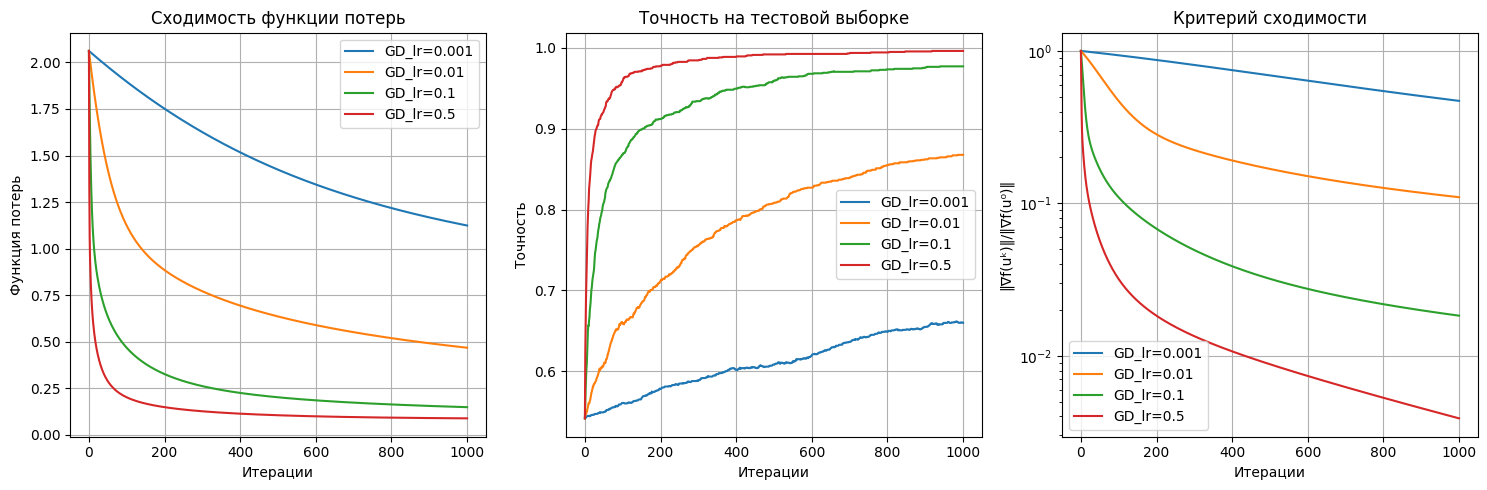

Сравнение результатов:
GD_lr=0.001: Итерации=1000, Финальная точность=0.6597, Финальный лосс=1.1241
GD_lr=0.01: Итерации=1000, Финальная точность=0.8677, Финальный лосс=0.4675
GD_lr=0.1: Итерации=1000, Финальная точность=0.9772, Финальный лосс=0.1482
GD_lr=0.5: Итерации=1000, Финальная точность=0.9963, Финальный лосс=0.0881


In [48]:
learning_rates = [0.001, 0.01, 0.1, 0.5]
results = []

for lr in learning_rates:
    optimizer = GradientDescent(lr=lr, name=f"GD_lr={lr}")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    results.append(result)

plt.figure(figsize=(15, 5))

# 1. График функции потерь
plt.subplot(1, 3, 1)
for result in results:
    plt.plot(result['num_iters'], result['Loss'], label=result['name'])
plt.xlabel('Итерации')
plt.ylabel('Функция потерь')
plt.title('Сходимость функции потерь')
plt.legend()
plt.grid(True)

# 2. График точности
plt.subplot(1, 3, 2)
for result in results:
    plt.plot(result['num_iters'], result['Accuracy'], label=result['name'])
plt.xlabel('Итерации')
plt.ylabel('Точность')
plt.title('Точность на тестовой выборке')
plt.legend()
plt.grid(True)

# 3. График критерия сходимости
plt.subplot(1, 3, 3)
for result in results:
    plt.plot(result['num_iters'], result['Criterion'], label=result['name'])
plt.xlabel('Итерации')
plt.ylabel('‖∇f(uᵏ)‖/‖∇f(u⁰)‖')
plt.title('Критерий сходимости')
plt.legend()
plt.grid(True)
plt.yscale('log')

plt.tight_layout()
plt.show()

print("Сравнение результатов:")
for result in results:
    final_iter = len(result['Accuracy']) - 1
    print(f"{result['name']}: "
          f"Итерации={final_iter}, "
          f"Финальная точность={result['Accuracy'][-1]:.4f}, "
          f"Финальный лосс={result['Loss'][-1]:.4f}")

GD lr=1e-3: 100%|██████████| 1000/1000 [00:02<00:00, 427.98it/s, Loss=1.12, Accuracy=0.66, Grad norm=0.47]


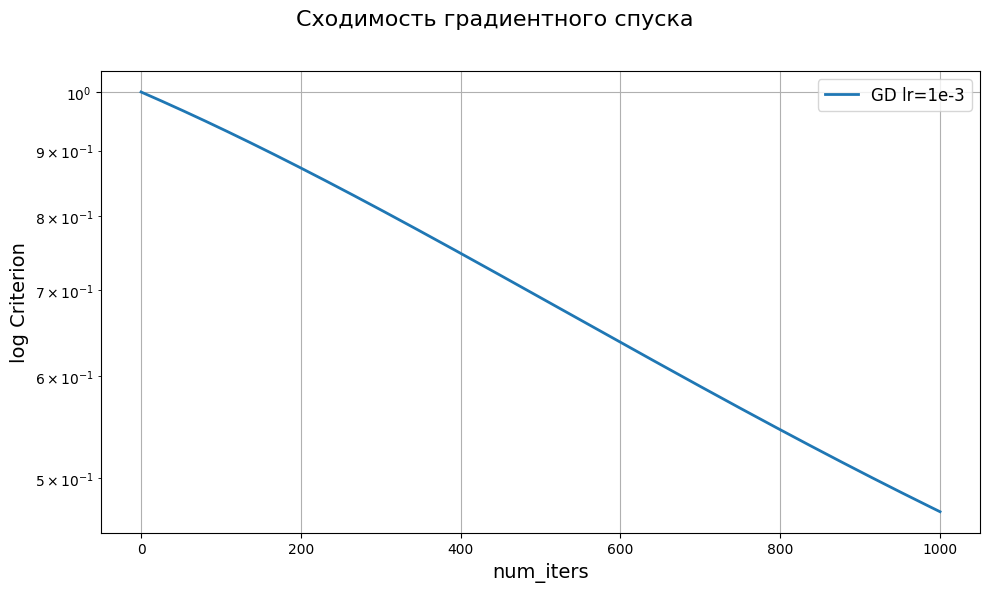

In [49]:
grad_opt = GradientDescent(lr=1e-3, name='GD lr=1e-3')
gd_res_baseline = test_optimizer(grad_opt)
plot_results([gd_res_baseline], 'Cходимость градиентного спуска')

In [66]:
def dynamic_lr(initial_gamma, delta):
    return lambda k: initial_gamma / (k + delta)

def dynamic_lr_sqrt(initial_gamma, delta):
    return lambda k: initial_gamma / (np.sqrt(k) + delta)

Const_η=0.7730: 100%|██████████| 1000/1000 [00:02<00:00, 430.12it/s, Loss=0.0844, Accuracy=0.996, Grad norm=0.00175]


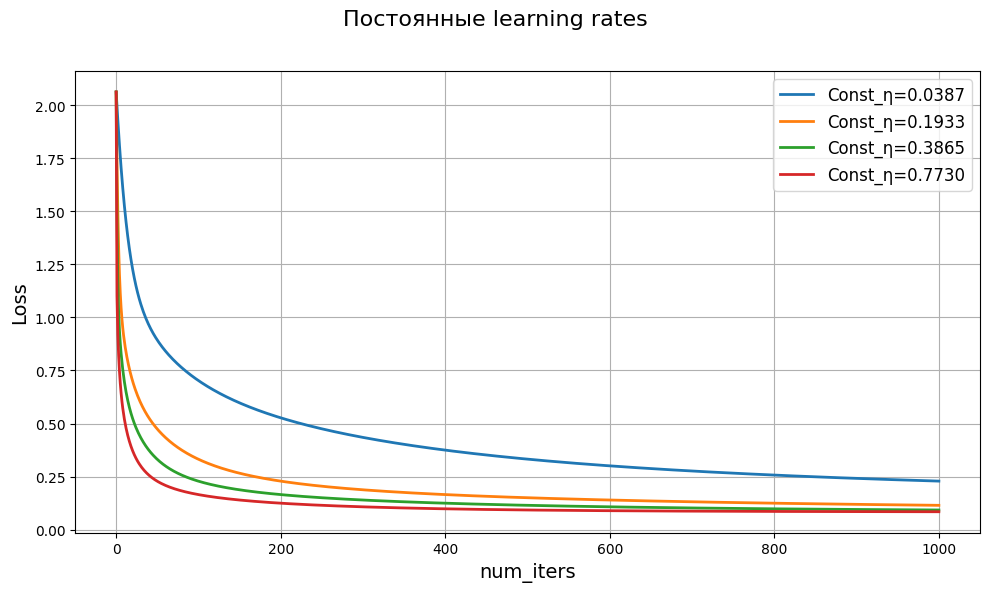

In [65]:
L = get_lipschitz(train_mush_x)
constant_lrs = [0.1/L, 0.5/L, 1.0/L, 2.0/L]

constant_results = []
for lr in constant_lrs:
    optimizer = GradientDescent(lr=lr, name=f"Const_η={lr:.4f}")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    constant_results.append(result)

plot_results(constant_results, "Постоянные learning rates", metrics_type=['Loss'])

Decay_η4: 100%|██████████| 1000/1000 [00:02<00:00, 433.29it/s, Loss=0.239, Accuracy=0.945, Grad norm=0.0429]


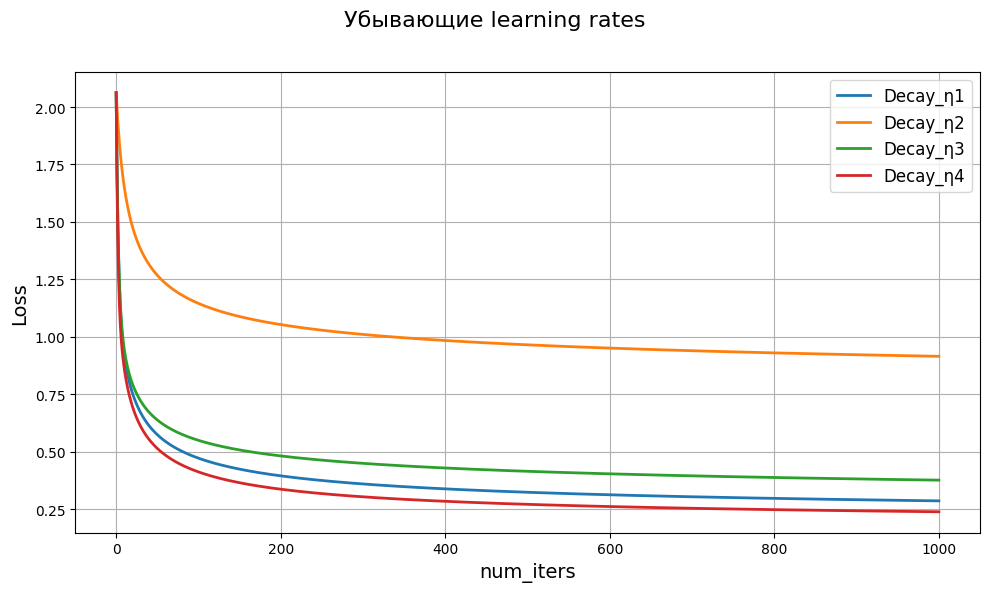

In [75]:
decaying_lrs = [
    dynamic_lr(20/L, 40),
    dynamic_lr(1/L, 10),
    dynamic_lr(10/L, 20),
    dynamic_lr(30/L, 50)
]

decaying_results = []
for i, lr_func in enumerate(decaying_lrs):
    optimizer = GradientDescent(lr=lr_func, name=f"Decay_η{i+1}")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    decaying_results.append(result)

plot_results(decaying_results, "Убывающие learning rates", metrics_type=['Loss'])

Sqrt_η4: 100%|██████████| 1000/1000 [00:02<00:00, 432.47it/s, Loss=0.122, Accuracy=0.988, Grad norm=0.0125]


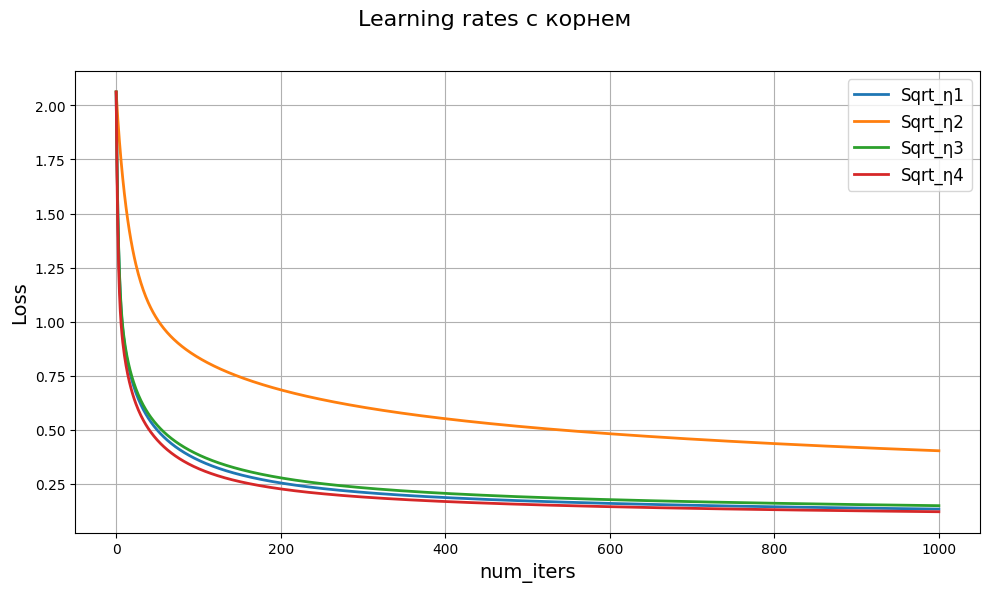

In [76]:
sqrt_lrs = [
    dynamic_lr_sqrt(20/L, 40),
    dynamic_lr_sqrt(1/L, 10),
    dynamic_lr_sqrt(10/L, 20),
    dynamic_lr_sqrt(30/L, 50)
]

sqrt_results = []
for i, lr_func in enumerate(sqrt_lrs):
    optimizer = GradientDescent(lr=lr_func, name=f"Sqrt_η{i+1}")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    sqrt_results.append(result)

plot_results(sqrt_results, "Learning rates с корнем", metrics_type=['Loss'])

Baseline_η=0.01: 100%|██████████| 1000/1000 [00:02<00:00, 345.55it/s, Loss=0.703, Accuracy=0.783, Grad norm=0.195]


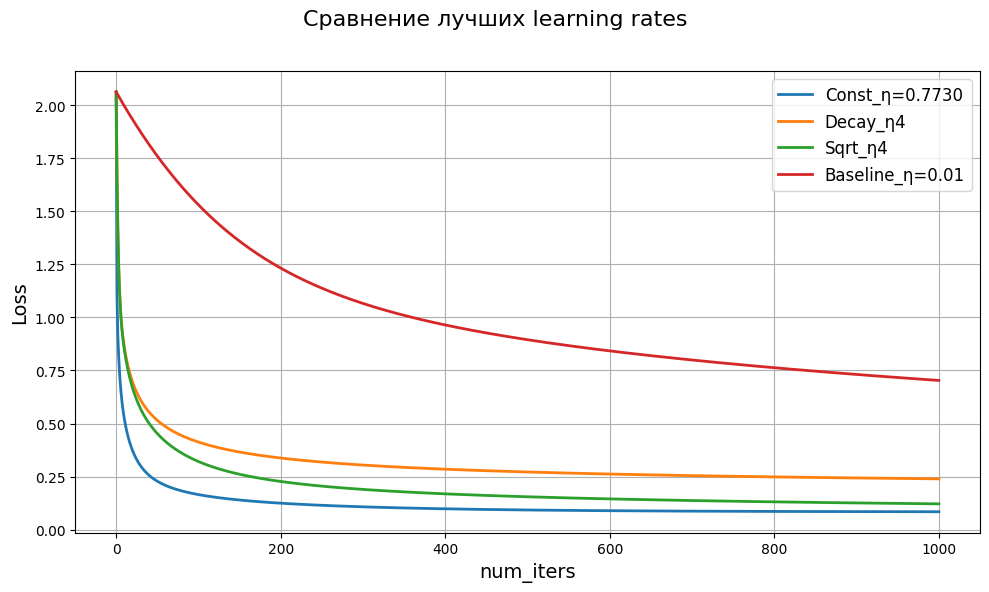

In [77]:
baseline_optimizer = GradientDescent(lr=0.01/L, name="Baseline_η=0.01")
baseline_result = test_optimizer(baseline_optimizer, max_iters=1000, stop_criterion=1e-8)

best_results = [
    min(constant_results, key=lambda x: x['Loss'][-1]),
    min(decaying_results, key=lambda x: x['Loss'][-1]),
    min(sqrt_results, key=lambda x: x['Loss'][-1]),
    baseline_result
]

plot_results(best_results, "Сравнение лучших learning rates", metrics_type=['Loss'])

In [80]:
best_final_gd_res = min(constant_results + decaying_results + sqrt_results, key=lambda x: x['Loss'][-1])
print(best_final_gd_res['name'])

Const_η=0.7730


### Задача 3 (1 балл)

Рассмотрим метод тяжёлого шарика (Heavy Ball)

$$ w^{k+1} = w^k - \gamma_k \nabla \mathcal{L}(w^k) + \tau_k (w^k - w^{k-1}) $$

- Реализуйте шаг метода тяжёлого шарика
- Используйте шаг $\gamma = \frac{1}{L}$.
1. Рассмотрите моментум  $\tau = \frac{\sqrt{L} - \sqrt{\mu}}{\sqrt{L} + \sqrt{\mu}}$ и несколько моментумов в его окрестности: $s \cdot \tau$, где $s \in [0.9, 1.1]$. Рассмотрите не менее 3-х окрестностей.
2. Рассмотрите моментумы равные  $\frac{k}{k+3}$, $\frac{k}{k+2}$, $\frac{k}{k+1}$ ($k$ — номер итерации).
3. Сравните полученные результаты.

In [134]:
class HeavyBall(ManualSolver):
    def __init__(self, lr, beta, init_w, name) -> None:
        super().__init__(lr, name, True, False)
        self.beta = beta if isinstance(beta, Callable) else lambda _: beta
        self.w_prev = init_w

    def step(self, w: np.ndarray, k: int, grad_f: np.ndarray, hess_f: None) -> np.ndarray:
        learning_rate = self.lr(k)
        beta_val = self.beta(k)
        new_w = w - learning_rate * grad_f + beta_val * (w - self.w_prev)
        self.w_prev = w.copy()
        return new_w
L = get_lipschitz(train_mush_x)
gamma = 1 / L

HB_t_1.05t: 100%|██████████| 1000/1000 [00:02<00:00, 426.52it/s, Loss=0.0834, Accuracy=0.996, Grad norm=0.000185]


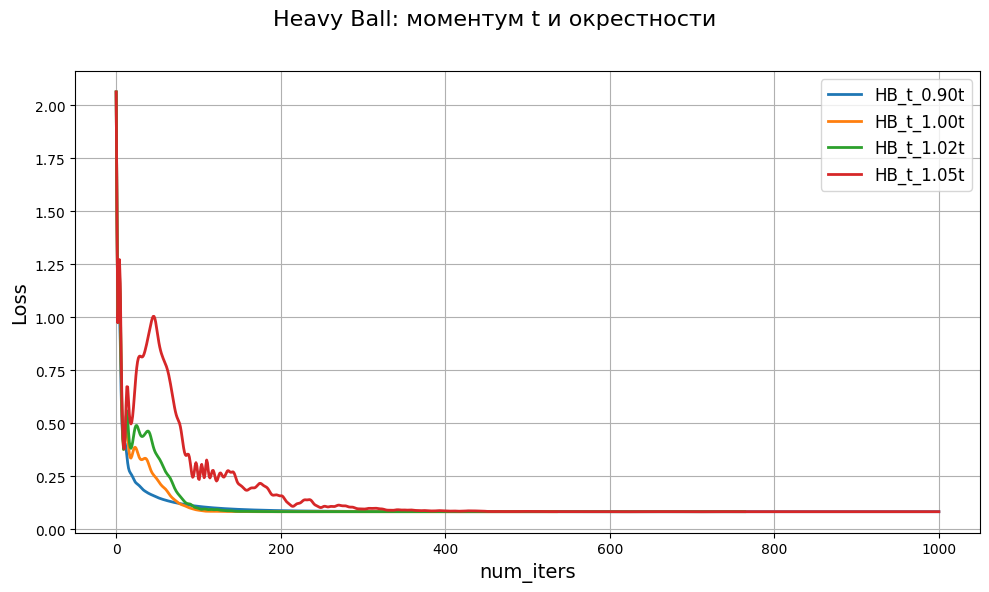

In [86]:
t = (np.sqrt(L) - np.sqrt(lambda_mush)) / (np.sqrt(L) + np.sqrt(lambda_mush))
momentum_factors = [0.9, 1.0, 1.02, 1.05]
momentums_1 = [s * t for s in momentum_factors]

hb_results_1 = []
for i, momentum_val in enumerate(momentums_1):
    optimizer = HeavyBall(lr=gamma, beta=momentum_val, init_w=start_w_mush,
                         name=f"HB_t_{momentum_factors[i]:.2f}t")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    hb_results_1.append(result)

plot_results(hb_results_1, "Heavy Ball: моментум t и окрестности", metrics_type=['Loss'])

HB_k/(k+1): 100%|██████████| 1000/1000 [00:02<00:00, 422.55it/s, Loss=0.0854, Accuracy=0.996, Grad norm=0.00881]


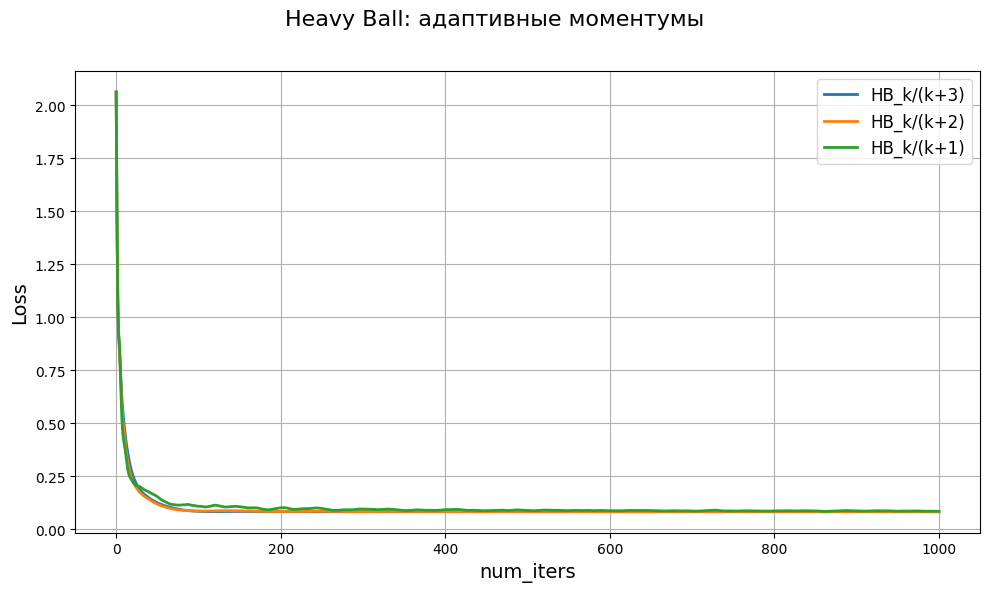

In [88]:
def beta_k_s(s):
    return lambda k: k / (k + s)

hb_results_2 = []
s_values = [3, 2, 1]

for s in s_values:
    beta_func = beta_k_s(s)
    optimizer = HeavyBall(lr=gamma, beta=beta_func, init_w=start_w_mush,
                         name=f"HB_k/(k+{s})")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    hb_results_2.append(result)

plot_results(hb_results_2, "Heavy Ball: адаптивные моментумы", metrics_type=['Loss'])

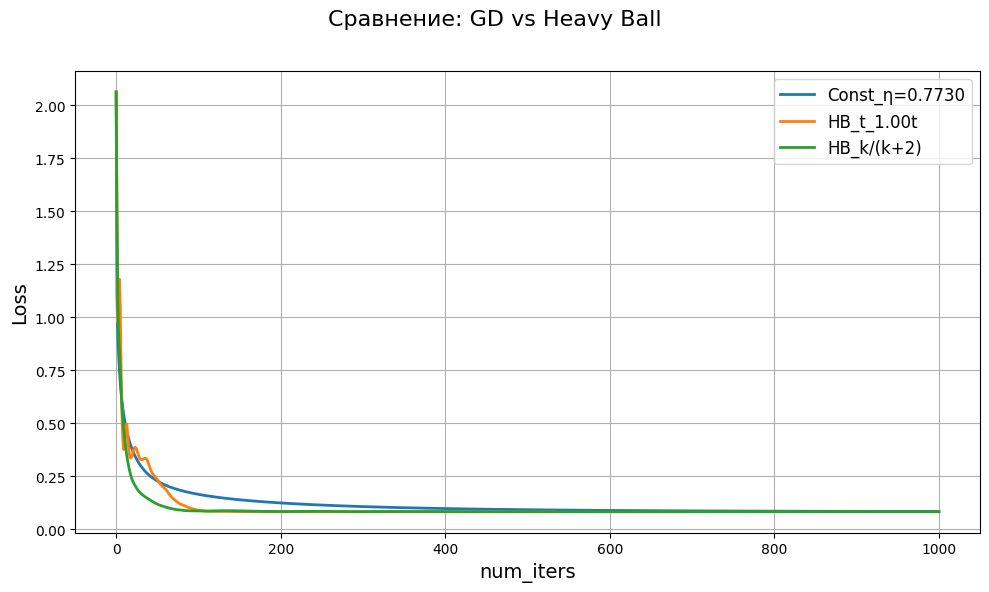

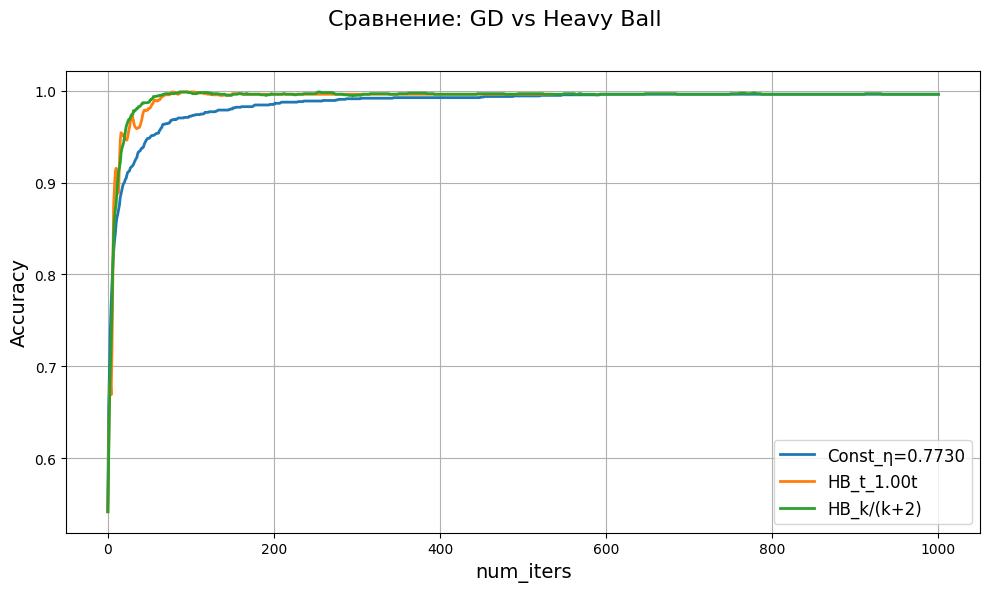

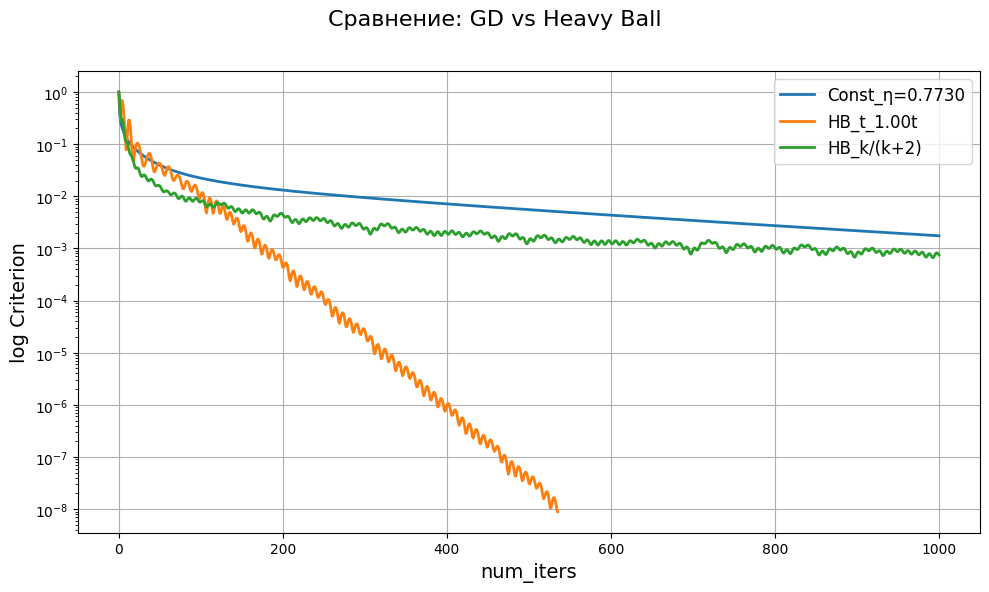

РЕЗУЛЬТАТЫ СРАВНЕНИЯ:
Const_η=0.7730:
  Итерации: 1000
  Финальная точность: 0.9963
  Финальный лосс: 0.0844
  Критерий сходимости: 1.75e-03

HB_t_1.00t:
  Итерации: 535
  Финальная точность: 0.9963
  Финальный лосс: 0.0834
  Критерий сходимости: 8.92e-09

HB_k/(k+2):
  Итерации: 1000
  Финальная точность: 0.9963
  Финальный лосс: 0.0833
  Критерий сходимости: 7.48e-04



In [135]:
all_hb_results = hb_results_1 + hb_results_2

best_hb_1 = min(hb_results_1, key=lambda x: x['Loss'][-1])
best_hb_2 = min(hb_results_2, key=lambda x: x['Loss'][-1])

comparison_results = [best_final_gd_res, best_hb_1, best_hb_2]

plot_results(comparison_results, "Сравнение: GD vs Heavy Ball", metrics_type=['Loss'])
plot_results(comparison_results, "Сравнение: GD vs Heavy Ball", metrics_type=['Accuracy'])
plot_results(comparison_results, "Сравнение: GD vs Heavy Ball", metrics_type=['Criterion'])

print("РЕЗУЛЬТАТЫ СРАВНЕНИЯ:")
print("=" * 50)
for result in comparison_results:
    iterations = len(result['Accuracy']) - 1
    accuracy = result['Accuracy'][-1]
    loss = result['Loss'][-1]
    criterion = result['Criterion'][-1]
    print(f"{result['name']}:")
    print(f"  Итерации: {iterations}")
    print(f"  Финальная точность: {accuracy:.4f}")
    print(f"  Финальный лосс: {loss:.4f}")
    print(f"  Критерий сходимости: {criterion:.2e}")
    print()

In [136]:
best_overall = min(comparison_results, key=lambda x: x['Loss'][-1])
best_final_hb_res = best_overall
print(best_overall['name'])

HB_k/(k+2)


### Задача 4 (2 балла)

Рассмотрим ускоренный градиентный метод (Nesterov Accelerated Gradient)

$$
\begin{align*}
& w_{k+1} = y_k - \gamma_k \nabla \mathcal{L}(y_k) \\
& y_{k+1} = w_{k+1} + \tau_k (w_{k+1} - w_k)
\end{align*}
$$

- Реализуйте шаг ускоренного градиентного метода
- Используйте шаг $\gamma = \frac{1}{L}$.
1. Рассмотрите моментум  $\tau = \frac{\sqrt{L} - \sqrt{\mu}}{\sqrt{L} + \sqrt{\mu}}$ и несколько моментумов в его окрестности: $s \cdot \tau$, где $s \in [0.9, 1.1]$. Рассмотрите не менее 3-х окрестностей.
2. Рассмотрите моментумы равные  $\frac{k}{k+3}$, $\frac{k}{k+2}$, $\frac{k}{k+1}$ ($k$ — номер итерации).
3. Сравните полученные результаты.

In [95]:
class NAG(ManualSolver):
    def __init__(self, lr, beta, init_w, name) -> None:
        super().__init__(lr, name, False, False)
        self.beta = beta if isinstance(beta, Callable) else lambda _: beta
        self.w_prev = init_w
        self.y_prev = init_w

    def step(self, w: np.ndarray, k: int, grad_f: None, hess_f: None) -> np.ndarray:

        learning_rate = self.lr(k)
        beta_val = self.beta(k)

        y_k = w + beta_val * (w - self.w_prev)

        grad_y = mush_grad(y_k)

        w_new = y_k - learning_rate * grad_y

        self.w_prev = w.copy()
        self.y_prev = y_k.copy()

        return w_new

NAG_β_1.05β: 100%|██████████| 1000/1000 [00:03<00:00, 264.19it/s, Loss=0.0834, Accuracy=0.996, Grad norm=9.6e-6]


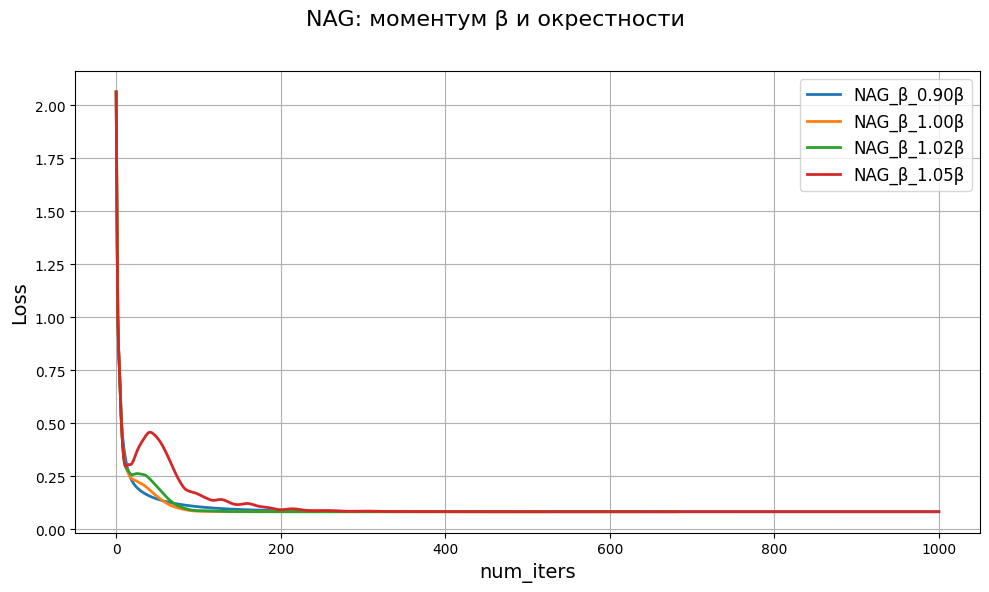

In [101]:
# 1.
beta_val = (np.sqrt(L) - np.sqrt(lambda_mush)) / (np.sqrt(L) + np.sqrt(lambda_mush))
beta_factors = [0.9, 1.0, 1.02, 1.05]
betas_1 = [s * beta_val for s in beta_factors]

nag_results_1 = []
for i, beta in enumerate(betas_1):
    optimizer = NAG(lr=gamma, beta=beta, init_w=start_w_mush,
                   name=f"NAG_β_{beta_factors[i]:.2f}β")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    nag_results_1.append(result)

plot_results(nag_results_1, "NAG: моментум β и окрестности", metrics_type=['Loss'])

NAG_k/(k+1): 100%|██████████| 1000/1000 [00:02<00:00, 378.85it/s, Loss=0.0837, Accuracy=0.996, Grad norm=0.00121]


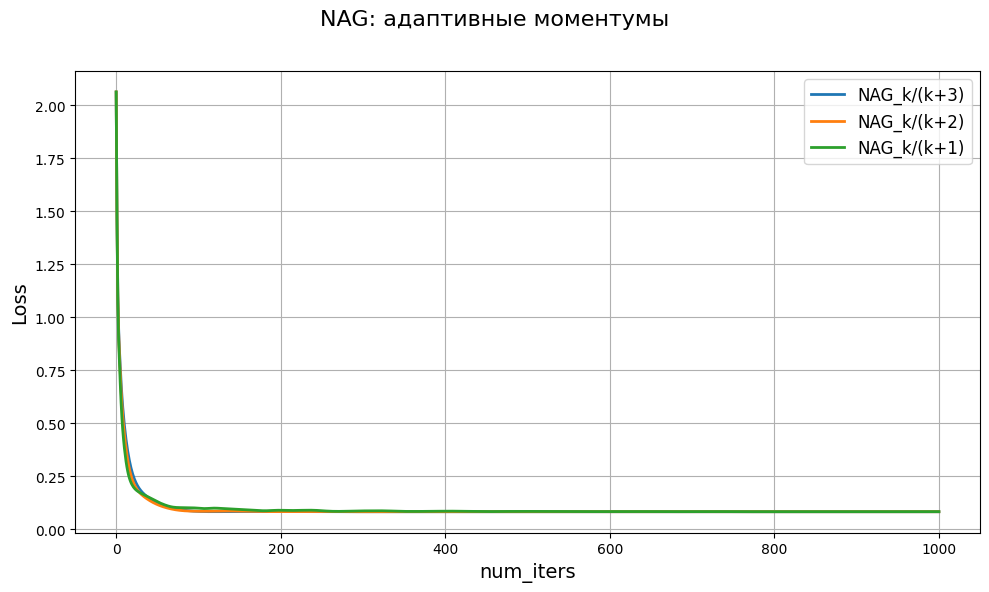

In [102]:
# 2.
def beta_k_s(s):
    return lambda k: k / (k + s)

nag_results_2 = []
s_values = [3, 2, 1]

for s in s_values:
    beta_func = beta_k_s(s)
    optimizer = NAG(lr=gamma, beta=beta_func, init_w=start_w_mush,
                   name=f"NAG_k/(k+{s})")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    nag_results_2.append(result)

plot_results(nag_results_2, "NAG: адаптивные моментумы", metrics_type=['Loss'])


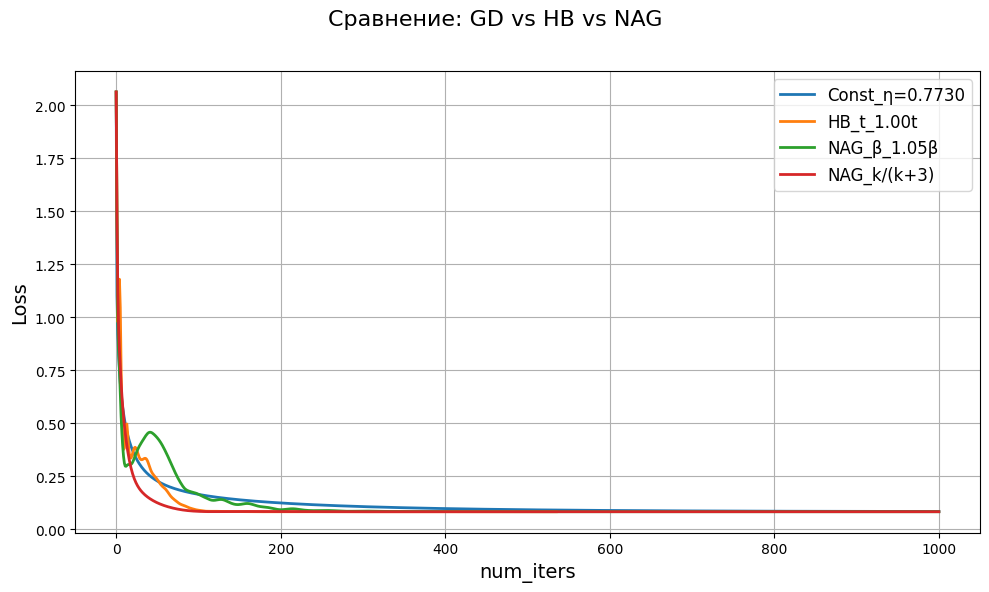

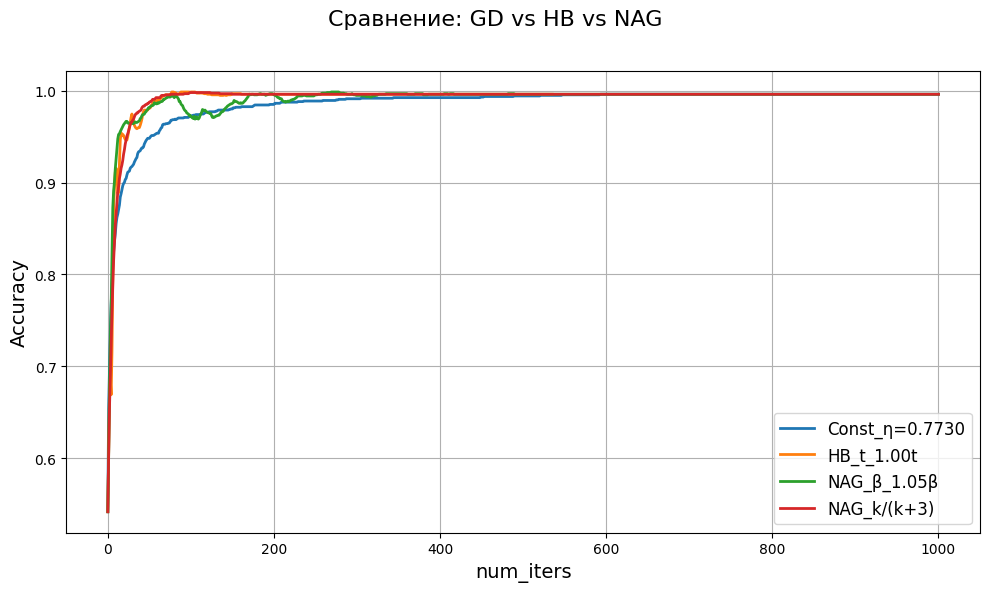

РЕЗУЛЬТАТЫ СРАВНЕНИЯ МЕТОДОВ:
GD: Const_η=0.7730
  Итерации: 1000 | Точность: 0.9963 | Лосс: 0.0844 | Критерий: 1.75e-03

Heavy Ball: HB_t_1.00t
  Итерации: 535 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 8.92e-09

NAG (окрестности β): NAG_β_1.05β
  Итерации: 1000 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 9.60e-06

NAG (адаптивный): NAG_k/(k+3)
  Итерации: 1000 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 4.55e-05



In [137]:
# 3.
all_nag_results = nag_results_1 + nag_results_2

best_nag_1 = min(nag_results_1, key=lambda x: x['Loss'][-1])
best_nag_2 = min(nag_results_2, key=lambda x: x['Loss'][-1])

comparison_results = [best_final_gd_res, best_hb_1, best_nag_1, best_nag_2]

plot_results(comparison_results, "Сравнение: GD vs HB vs NAG", metrics_type=['Loss'])
plot_results(comparison_results, "Сравнение: GD vs HB vs NAG", metrics_type=['Accuracy'])

print("РЕЗУЛЬТАТЫ СРАВНЕНИЯ МЕТОДОВ:")
print("=" * 60)
methods = [
    ("GD", best_final_gd_res),
    ("Heavy Ball", best_hb_1),
    ("NAG (окрестности β)", best_nag_1),
    ("NAG (адаптивный)", best_nag_2)
]

for method_name, result in methods:
    iterations = len(result['Accuracy']) - 1
    accuracy = result['Accuracy'][-1]
    loss = result['Loss'][-1]
    criterion = result['Criterion'][-1]
    print(f"{method_name}: {result['name']}")
    print(f"  Итерации: {iterations:3d} | Точность: {accuracy:.4f} | Лосс: {loss:.4f} | Критерий: {criterion:.2e}")
    print()

In [138]:
best_overall = min([result for _, result in methods], key=lambda x: x['Loss'][-1])
best_final_nag_res = best_overall
print(best_overall['name'])

NAG_β_1.05β


### Задача 5 (1 балла)

Рассмотрим один из самых известных методов второго порядка - Метод Ньютона (Newton's method):

$$
w_{k+1} = w_k - \nabla^2\mathcal{L}(w^k)^{-1} \nabla \mathcal{L}(w^k)
$$

А точнее, его модификацию - демпфированный метод Ньютона (Dumped Newton's method):

$$
w_{k+1} = w_k - \gamma_k \nabla^2\mathcal{L}(w^k)^{-1} \nabla \mathcal{L}(w^k)
$$

- Реализуйте шаг демпфированного метода Ньютона
1.  Протестируйте различные $\gamma_k = \gamma = \frac{s}{L}$, где $s \in [0.5, 1.5]$, $L$ - константа липшица в задаче. Рассмотрите не менее 3-х $s$.
2. Сравните полученные результаты.

In [109]:
class Newton(ManualSolver):
    def __init__(self, lr, name) -> None:
        super().__init__(lr, name, True, True)

    def step(self, w: np.ndarray, k: int, grad_f: np.ndarray, hess_f: np.ndarray) -> np.ndarray:

        learning_rate = self.lr(k)

        try:
            direction = np.linalg.solve(hess_f, -grad_f)
        except np.linalg.LinAlgError:
            direction = -np.linalg.pinv(hess_f) @ grad_f

        w_new = w + learning_rate * direction

        return w_new

L = get_lipschitz(train_mush_x)

Newton_γ=1.05/L:   4%|▎         | 35/1000 [00:00<00:11, 84.22it/s, Loss=0.0834, Accuracy=0.996, Grad norm=8.75e-9] 


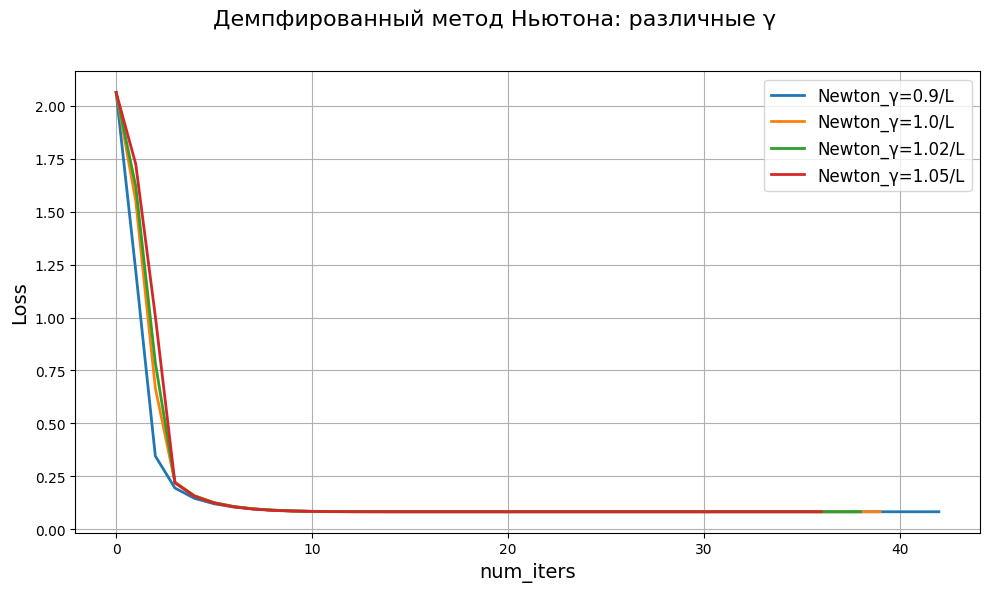

In [110]:
# 1.
s_values = [0.9, 1.0, 1.02, 1.05]
newton_results = []

for s in s_values:
    gamma_newton = s / L
    optimizer = Newton(lr=gamma_newton, name=f"Newton_γ={s}/L")
    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    newton_results.append(result)

plot_results(newton_results, "Демпфированный метод Ньютона: различные γ", metrics_type=['Loss'])

In [117]:
# 2.
for result in newton_results:
    iterations = len(result['Accuracy']) - 1
    accuracy = result['Accuracy'][-1]
    loss = result['Loss'][-1]
    criterion = result['Criterion'][-1]
    s_value = result['name'].split('=')[1].split('/')[0]
    print(f"γ = {s_value}/L:")
    print(f"  Итерации: {iterations:3d} | Точность: {accuracy:.4f} | Лосс: {loss:.4f} | Критерий: {criterion:.2e}")
    print()

best_newton = min(newton_results, key=lambda x: x['Loss'][-1])
best_s = best_newton['name'].split('=')[1].split('/')[0]

γ = 0.9/L:
  Итерации:  42 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 9.59e-09

γ = 1.0/L:
  Итерации:  39 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 6.57e-09

γ = 1.02/L:
  Итерации:  38 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 7.09e-09

γ = 1.05/L:
  Итерации:  36 | Точность: 0.9963 | Лосс: 0.0834 | Критерий: 8.75e-09



In [128]:
best_final_newton_res = best_newton
print(f"{best_s}/L")

1.02/L


### Сравнение лучших реализаций

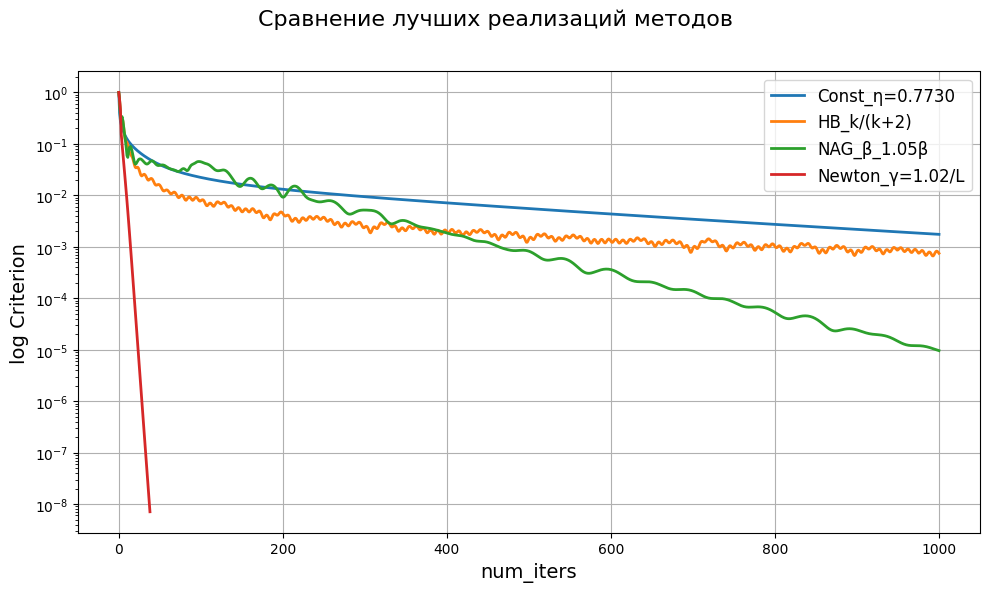

In [139]:
final_results = [best_final_gd_res, best_final_hb_res, best_final_nag_res, best_final_newton_res]
plot_results(final_results, 'Сравнение лучших реализаций методов', metrics_type=['Criterion'])

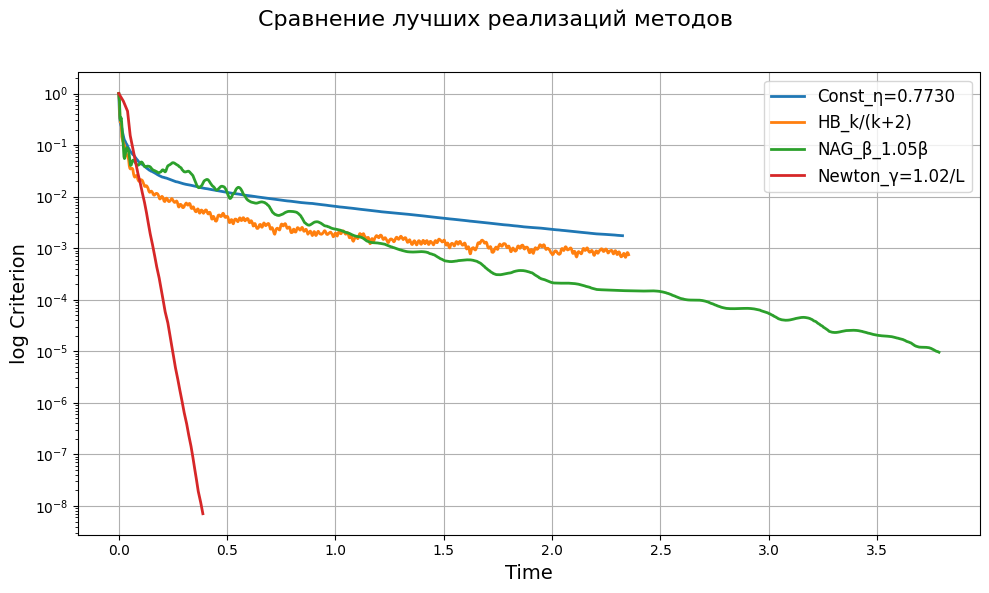

In [140]:
final_results = [best_final_gd_res, best_final_hb_res, best_final_nag_res, best_final_newton_res]
plot_results(final_results, 'Сравнение лучших реализаций методов', metrics_type=['Criterion'], x='Time')

### Ваши выводы (до 0.5 баллов):

1. Почему предложено выбирать $\gamma = \frac{s}{L}$, $\tau = \frac{\sqrt{L} - \sqrt{\mu}}{\sqrt{L} + \sqrt{\mu}}$?
Обратная пропорциональность константе липшица дает гарантированную сходимость: gamma < 2/L. Формула моментума - актуальна для квадратичных функций.
2. Почему наблюдаются различия в графиках по количеству итераций и по времени?
Методы 2-го порядка сходятся за меньшее число итераций благодаря квадратичной сходимости. Ускоренные методы (NAG, Heavy Ball) требуют меньше итераций.
3. Выбор метода зависит от размера данных, требуемой точности.

### Задача 6* (1 балл)

Метод проксимального градиентного спуска используется для оптимизации композитной функции потерь
$$
h(w) = f(w) + g(w),
$$
где $f(w)$ является выпуклой дифференцируемой функцией на своей области определения. Особенностью является то, что $g(w)$ не обязательно должна быть дифференцируема всюду на своём множестве определения.  

Мы решаем задачу вида
$$
\min_{w\in \mathbb{R}^d}\{f(w) + R(w)\},
$$
где $R(w)$ - выпуклый (возможно негладкий) регуляризатор.

Обновление параметров осуществляется по схеме
$$
w_{k+1} = prox_{\gamma R}(w_k - \gamma\nabla f(w)),
$$
где проксимальный оператор определяется как
$$
prox_{\gamma R}(v) = \arg\min_{w\in \mathbb{R}^d}\left\{\dfrac{1}{2\gamma}\|w - v\|^2 + R(w) \right\}.
$$

* Реализуйте шаг проксимального градиентного спуска для различных видов $R(w)$ (L1, L2-регуляризация).
1. Протестируйте различные $\gamma_k = \gamma = \frac{s}{L}$, где $L$ определяется согласно $R(w)$.
2. Сравните полученные результаты.

In [141]:
class ProximalGradient(ManualSolver):
    def __init__(self, lr, reg_type, reg_lambda, name) -> None:
        super().__init__(lr, name, True, False)
        self.reg_type = reg_type  # 'l1' или 'l2'
        self.reg_lambda = reg_lambda

    def proximal_operator(self, v, gamma):
        """Проксимальный оператор для L1 или L2 регуляризации"""
        if self.reg_type == 'l2':
            # Для L2: prox_{γλ‖·‖²}(v) = v / (1 + 2γλ)
            return v / (1 + 2 * gamma * self.reg_lambda)
        elif self.reg_type == 'l1':
            # Для L1: soft-thresholding оператор
            return np.sign(v) * np.maximum(np.abs(v) - gamma * self.reg_lambda, 0)
        else:
            raise ValueError("Поддерживаются только 'l1' и 'l2' регуляризации")

    def step(self, w: np.ndarray, k: int, grad_f: np.ndarray, hess_f: None) -> np.ndarray:
        learning_rate = self.lr(k)
        v = w - learning_rate * grad_f
        w_new = self.proximal_operator(v, learning_rate)

        return w_new

# Определяем функцию потерь без регуляризации для проксимального метода
def mush_f_smooth(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> float:
    n = len(y)
    exponents = np.exp(-y * (x @ w))
    log_loss = np.mean(np.log(1 + exponents))
    return log_loss

def mush_grad_smooth(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> np.ndarray:
    n = len(y)
    exponents = np.exp(-y * (x @ w))
    sigmoid_terms = exponents / (1 + exponents)
    grad_log_loss = -(1/n) * (x.T @ (y * sigmoid_terms))
    return grad_log_loss

# Переопределяем функции для использования в тестировании
def mush_f_proximal(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> float:
    smooth_loss = mush_f_smooth(w, x, y)
    return smooth_loss

def mush_grad_proximal(w: np.ndarray, x: np.ndarray = train_mush_x, y: np.ndarray = train_mush_y) -> np.ndarray:
    return mush_grad_smooth(w, x, y)

Константа Липшица для гладкой части L = 2.5872260889612626


Prox_L2_γ=1.5/L: 100%|██████████| 1000/1000 [00:03<00:00, 273.09it/s, Loss=0.315, Accuracy=0.917, Grad norm=0.16]


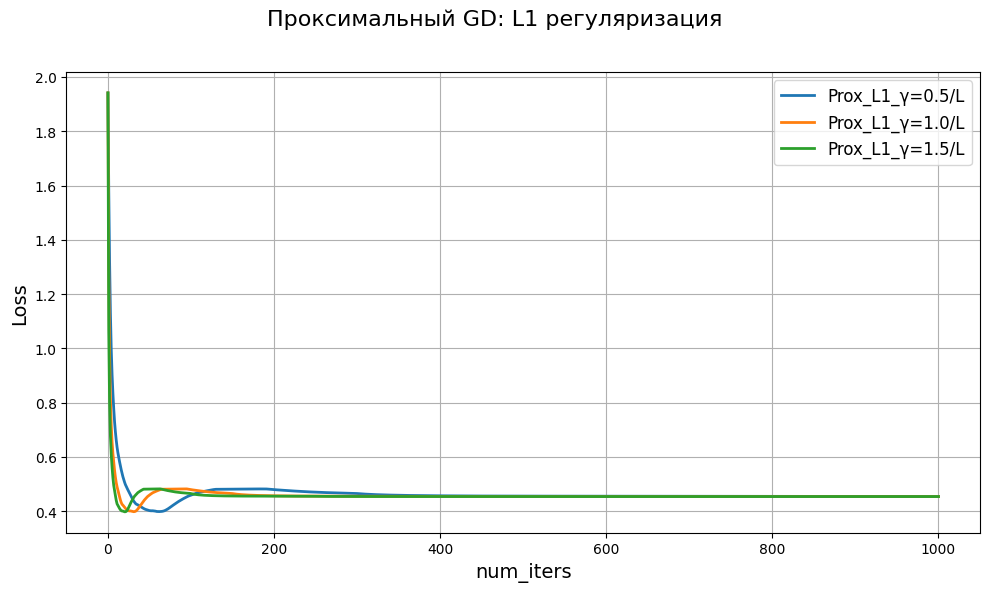

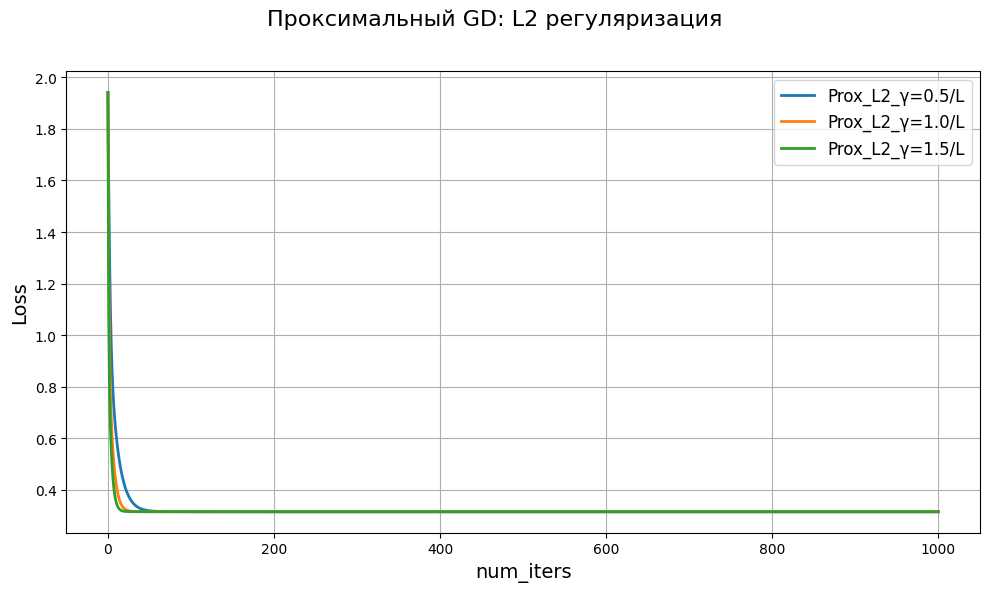

In [145]:
# 1.
L_smooth = get_lipschitz(train_mush_x)
s_values = [0.5, 1.0, 1.5]
reg_lambda = 0.1

print(f"Константа Липшица для гладкой части L = {L_smooth}")

# Тестируем L1 регуляризацию
l1_results = []
for s in s_values:
    gamma_prox = s / L_smooth
    optimizer = ProximalGradient(lr=gamma_prox, reg_type='l1', reg_lambda=reg_lambda,
                                name=f"Prox_L1_γ={s}/L")
    mush_f_old, mush_grad_old = mush_f, mush_grad
    mush_f, mush_grad = mush_f_proximal, mush_grad_proximal

    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    l1_results.append(result)

    mush_f, mush_grad = mush_f_old, mush_grad_old

# Тестируем L2 регуляризацию
l2_results = []
for s in s_values:
    gamma_prox = s / L_smooth
    optimizer = ProximalGradient(lr=gamma_prox, reg_type='l2', reg_lambda=reg_lambda,
                                name=f"Prox_L2_γ={s}/L")
    mush_f_old, mush_grad_old = mush_f, mush_grad
    mush_f, mush_grad = mush_f_proximal, mush_grad_proximal

    result = test_optimizer(optimizer, max_iters=1000, stop_criterion=1e-8)
    l2_results.append(result)

    mush_f, mush_grad = mush_f_old, mush_grad_old

plot_results(l1_results, "Проксимальный GD: L1 регуляризация", metrics_type=['Loss'])
plot_results(l2_results, "Проксимальный GD: L2 регуляризация", metrics_type=['Loss'])

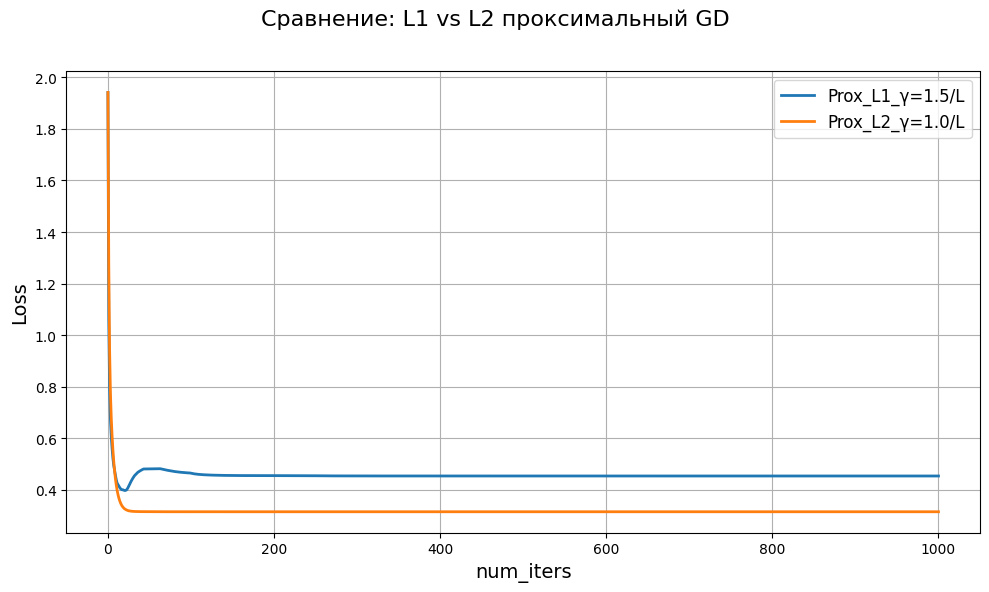

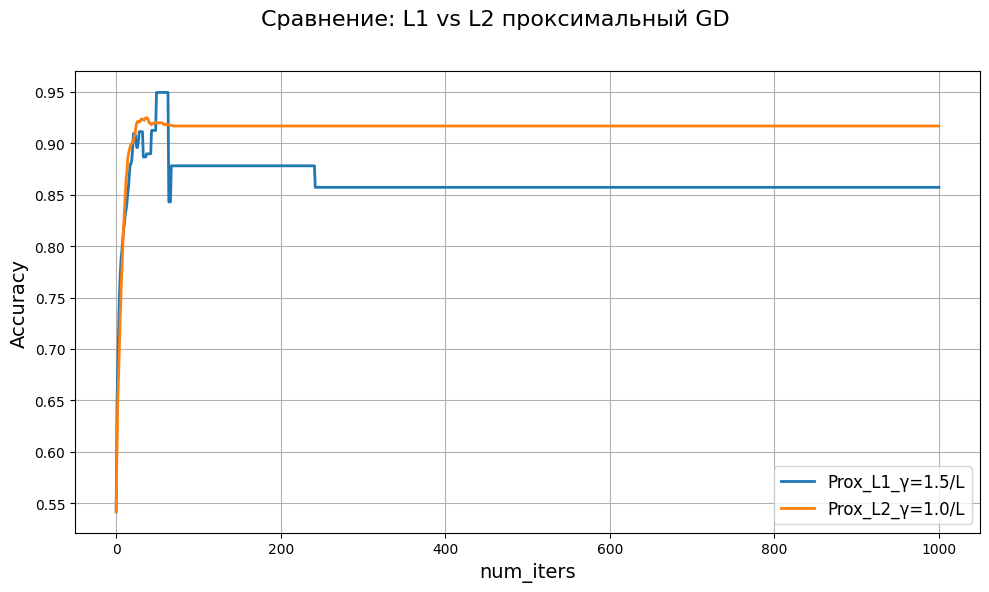

L1 регуляризация (лучший результат):
  Разреженность: 96.43% нулевых весов
  Точность: 0.8572
  Лосс: 0.4541
  Итерации: 1000

L2 регуляризация (лучший результат):
  Точность: 0.9169
  Лосс: 0.3154
  Итерации: 1000

Сравнение с обычной L2 регуляризацией (λ=0.0025872260889612626):
  Точность: 0.9963
  Лосс: 0.0844


In [146]:
# 2.
best_l1 = min(l1_results, key=lambda x: x['Loss'][-1])
best_l2 = min(l2_results, key=lambda x: x['Loss'][-1])

prox_comparison = [best_l1, best_l2]

plot_results(prox_comparison, "Сравнение: L1 vs L2 проксимальный GD", metrics_type=['Loss'])
plot_results(prox_comparison, "Сравнение: L1 vs L2 проксимальный GD", metrics_type=['Accuracy'])

# Для L1 регуляризации анализируем разреженность
best_l1_w = best_l1['W']
sparsity_l1 = np.mean(np.abs(best_l1_w) < 1e-6)

print(f"L1 регуляризация (лучший результат):")
print(f"  Разреженность: {sparsity_l1:.2%} нулевых весов")
print(f"  Точность: {best_l1['Accuracy'][-1]:.4f}")
print(f"  Лосс: {best_l1['Loss'][-1]:.4f}")
print(f"  Итерации: {len(best_l1['Accuracy']) - 1}")

print(f"\nL2 регуляризация (лучший результат):")
print(f"  Точность: {best_l2['Accuracy'][-1]:.4f}")
print(f"  Лосс: {best_l2['Loss'][-1]:.4f}")
print(f"  Итерации: {len(best_l2['Accuracy']) - 1}")

# Сравниваем с обычной L2 регуляризацией
print(f"\nСравнение с обычной L2 регуляризацией (λ={lambda_mush}):")
print(f"  Точность: {best_final_gd_res['Accuracy'][-1]:.4f}")
print(f"  Лосс: {best_final_gd_res['Loss'][-1]:.4f}")

## Задание 3: Предсказание погоды в Австралии

Датасет содержит ежедневные наблюдения погоды в различных регионах Австралии за период в 10 лет.

Предсказываемым признаком является `RainTomorrow`: "Будет ли завтра дождь?". Это задача бинарной классификации.

Скачиваем датасет

In [147]:
import pandas as pd
import seaborn as sns

In [148]:
url = 'https://huggingface.co/Anm5/rainpred/resolve/main/weatherAUS.csv'
filename = 'weatherAUS.csv'

response = requests.get(url)
with open(filename, 'wb') as file:
    file.write(response.content)
df = pd.read_csv(filename)
df.head(5)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Задача 1 (3 балла): Анализ датасета

Датасет представляет собой табличные данные. В этом задании вы убедитесь, что основной объём работы в классификации таких данных с помощью методов машинного обучения состоит в анализе датасета и его признаков.

Давайте выведем общую информацию о признаках в датасете

In [149]:
df.info()
print(f"Number of NaN targets: {df['RainTomorrow'].isnull().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

Можно заметить, что для некоторых примеров в датасете отсутствует разметка. Поскольку мы решаем задачу классификации с учителем, эти примеры нас не интересуют.

**Удалите из датасета сэмплы с отсутствующим значением `RainTomorrow`**.

In [150]:
print(f"Размер датасета до удаления: {df.shape}")
df = df.dropna(subset=['RainTomorrow'])
print(f"Размер датасета после удаления: {df.shape}")
print("\nРаспределение целевой переменной RainTomorrow:")
print(df['RainTomorrow'].value_counts())
print(df['RainTomorrow'].value_counts(normalize=True))

Размер датасета до удаления: (145460, 23)
Размер датасета после удаления: (142193, 23)

Распределение целевой переменной RainTomorrow:
RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64
RainTomorrow
No     0.775819
Yes    0.224181
Name: proportion, dtype: float64


Выделим категориальные переменные

In [151]:
categorical = [var for var in df.columns if df[var].dtype=='O']
print('The categorical variables are :', categorical)
for feature in categorical:
    print(f"Number of unique {feature}:", df[feature].nunique())

The categorical variables are : ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
Number of unique Date: 3436
Number of unique Location: 49
Number of unique WindGustDir: 16
Number of unique WindDir9am: 16
Number of unique WindDir3pm: 16
Number of unique RainToday: 2
Number of unique RainTomorrow: 2


`RainTomorrow` является целевым признаком. `RainToday` нетрудно бинаризовать. Остальные признаки содержат большое количество значений.

В первом приближении, удалим признаки кроме `RainTomorrow`, `RainToday`.

**Важно:** датасет без категориальных признаков необходимо записать в отдельную переменную `df_numerical`. Исходный набор `df` пригодится в дополнительном задании.

**Бинаризуйте признаки `RainTomorrow`, `RainToday`. Остальные удалите**

In [152]:
df_original = df.copy()

df_numerical = df.copy()

df_numerical['RainTomorrow'] = df_numerical['RainTomorrow'].map({'Yes': 1, 'No': 0})
df_numerical['RainToday'] = df_numerical['RainToday'].map({'Yes': 1, 'No': 0})

categorical_to_remove = [var for var in categorical if var not in ['RainToday', 'RainTomorrow']]
df_numerical = df_numerical.drop(columns=categorical_to_remove)

print(f"Размер df_numerical после обработки: {df_numerical.shape}")
print("\nСтолбцы в df_numerical:")
print(df_numerical.columns.tolist())
print("\nПервые 5 строк df_numerical:")
print(df_numerical.head())

print("\nПроверка бинаризации:")
print("RainTomorrow values:", df_numerical['RainTomorrow'].unique())
print("RainToday values:", df_numerical['RainToday'].unique())

Размер df_numerical после обработки: (142193, 18)

Столбцы в df_numerical:
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']

Первые 5 строк df_numerical:
   MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  WindGustSpeed  \
0     13.4     22.9       0.6          NaN       NaN           44.0   
1      7.4     25.1       0.0          NaN       NaN           44.0   
2     12.9     25.7       0.0          NaN       NaN           46.0   
3      9.2     28.0       0.0          NaN       NaN           24.0   
4     17.5     32.3       1.0          NaN       NaN           41.0   

   WindSpeed9am  WindSpeed3pm  Humidity9am  Humidity3pm  Pressure9am  \
0          20.0          24.0         71.0         22.0       1007.7   
1           4.0          22.0         44.0         25.0       1010.6   
2     

Перейдём к численным признакам

In [153]:
numerical = [var for var in df.columns if df[var].dtype!='O']
round(df_numerical[numerical].describe(), 2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,141556.00,141871.00,140787.00,81350.00,74377.00,132923.00,140845.00,139563.00,140419.00,138583.00,128179.00,128212.00,88536.00,85099.00,141289.00,139467.00
mean,12.19,23.23,2.35,5.47,7.62,39.98,14.00,18.64,68.84,51.48,1017.65,1015.26,4.44,4.50,16.99,21.69
std,6.40,7.12,8.47,4.19,3.78,13.59,8.89,8.80,19.05,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.90,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.50,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.80,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70


Одним из важных аспектов обработки численных признаков является *опеределение выбросов (англ. outliers)*. С одной стороны, выбросы можно выделить для всех признаков. Однако, бывает полезно изучить, для каких фичей они более характерны. Это позволит избежать потери важной информации.

**Вам необходимо определить, для каких из численных признаков имеет смысл выделять выбросы.**

**Примечание:** Это можно сделать с помощью графика гистограммы. Отрисуйте зависимости всех числовых признаков от целевого `RainTomorrow`. По оси x отложите значения признака, по оси y - плотность `RainTomorrow` (в результате на рисунке будут 2 графика для каждого из бинарных значений). Для этого воспользуйтесь функцией `seaborn.histplot` с аргументом `stat='density'`. По виду графика можно интерпретировать, для каких признаков существуют значительные выбросы.

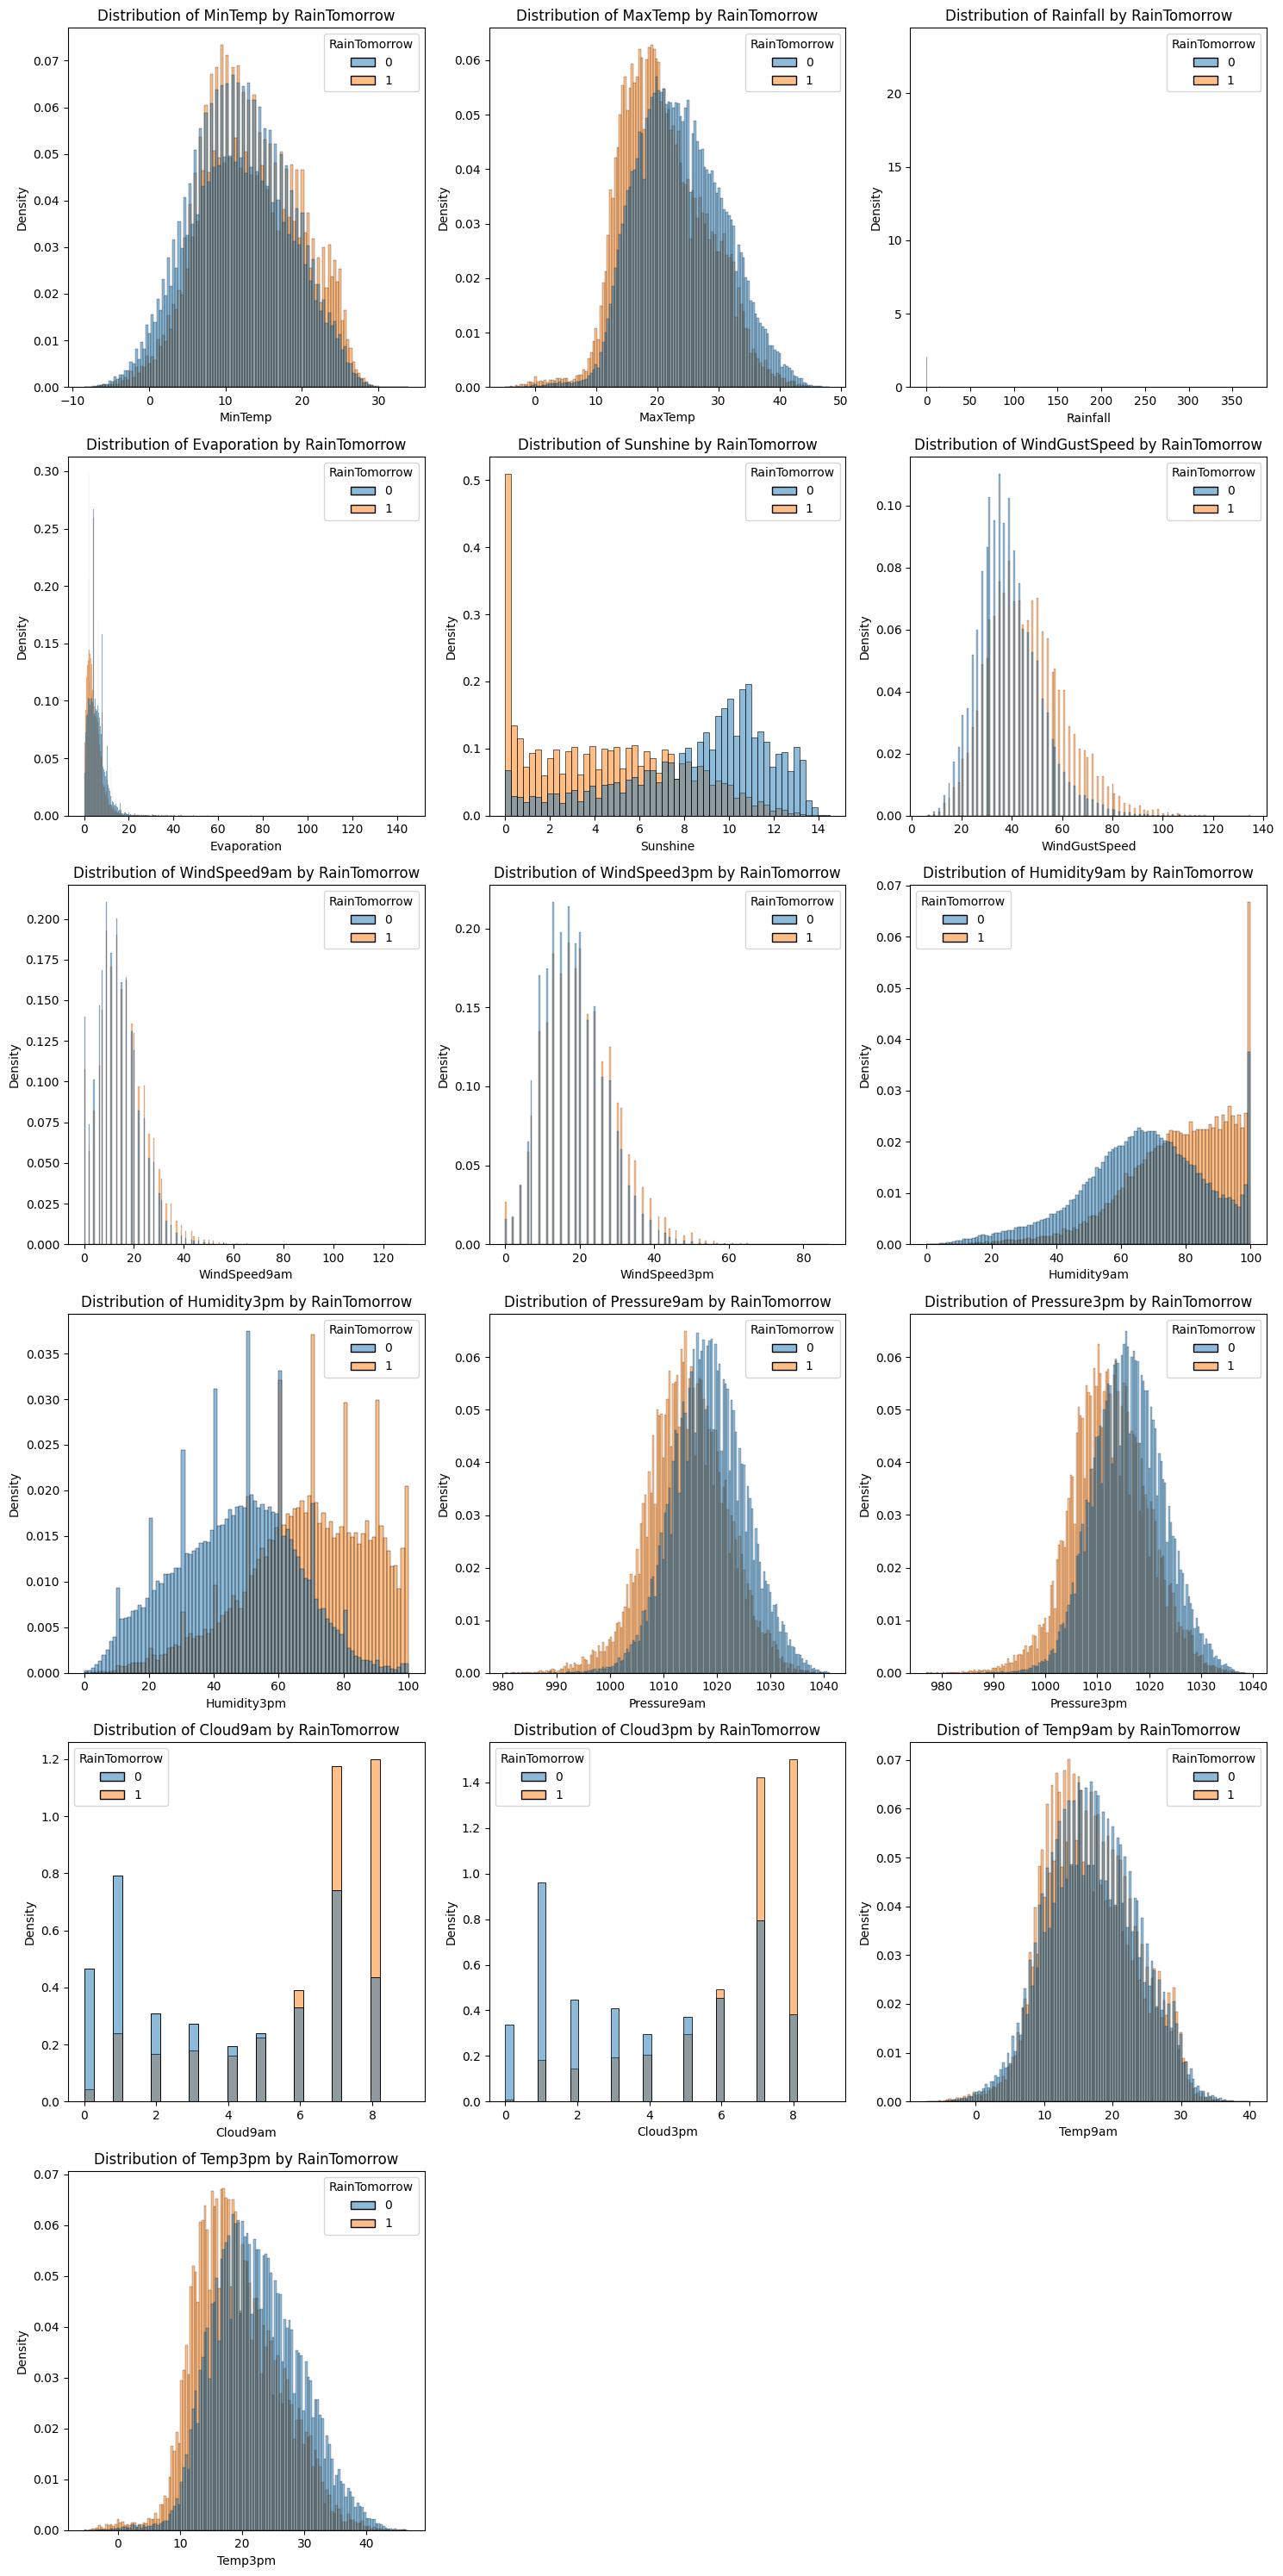


MinTemp:
  Выбросы: 62 (0.04%)
  Границы выбросов: [-6.20, 30.60]
Нормальное распределение

MaxTemp:
  Выбросы: 459 (0.32%)
  Границы выбросов: [2.45, 43.65]
Нормальное распределение

Rainfall:
  Выбросы: 25228 (17.74%)
  Границы выбросов: [-1.20, 2.00]
Обработать выбросы

Evaporation:
  Выбросы: 1954 (1.37%)
  Границы выбросов: [-4.60, 14.60]
Умеренное количество выбросов

Sunshine:
  Выбросы: 0 (0.00%)
  Границы выбросов: [-3.65, 19.15]
Нормальное распределение

WindGustSpeed:
  Выбросы: 3006 (2.11%)
  Границы выбросов: [5.50, 73.50]
Умеренное количество выбросов

WindSpeed9am:
  Выбросы: 1739 (1.22%)
  Границы выбросов: [-11.00, 37.00]
Умеренное количество выбросов

WindSpeed3pm:
  Выбросы: 2458 (1.73%)
  Границы выбросов: [-3.50, 40.50]
Умеренное количество выбросов

Humidity9am:
  Выбросы: 1419 (1.00%)
  Границы выбросов: [18.00, 122.00]
Нормальное распределение

Humidity3pm:
  Выбросы: 0 (0.00%)
  Границы выбросов: [-6.50, 109.50]
Нормальное распределение

Pressure9am:
  Выбросы

In [155]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_features = [var for var in numerical if var != 'RainTomorrow']

n_features = len(numerical_features)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    if i < len(axes):
        sns.histplot(data=df_numerical, x=feature, hue='RainTomorrow',
                    stat='density', common_norm=False, ax=axes[i])
        axes[i].set_title(f'Distribution of {feature} by RainTomorrow')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Density')

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

for feature in numerical_features:
    # Вычисляем статистики для анализа выбросов
    Q1 = df_numerical[feature].quantile(0.25)
    Q3 = df_numerical[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Считаем количество выбросов
    outliers = df_numerical[(df_numerical[feature] < lower_bound) | (df_numerical[feature] > upper_bound)]
    n_outliers = len(outliers)
    outlier_percentage = (n_outliers / len(df_numerical)) * 100

    print(f"\n{feature}:")
    print(f"  Выбросы: {n_outliers} ({outlier_percentage:.2f}%)")
    print(f"  Границы выбросов: [{lower_bound:.2f}, {upper_bound:.2f}]")

    if outlier_percentage > 5:  # Если выбросов больше 5%
        print(f"Обработать выбросы")
    elif outlier_percentage > 1:
        print(f"Умеренное количество выбросов")
    else:
        print(f"Нормальное распределение")

Графики признаков с выбросами имеют характерное *смещение (англ. skew)*. Для смещённых распределений, выбросы можно определить через *межквартильное расстояние (англ. Interquartile Range).*
$$
IQR = Q3 - Q1,
$$
где $Q3$ - третий квартиль, соответствующий порогу $75\%$, $Q1$ - первый квартиль, соответствующий порогу $25\%$.

Тогда выбросы определяют согласно правилу:
*  *Нижний выброс* - $x < Q1 - 1.5\cdot IQR$, $x$ - значение признака;
*  *Верхний выброс* - $x > Q3 + 1.5\cdot IQR$.

Если в результате получилось слишком много выбросов, значение $1.5$ можно увеличить, выделяя более "явные".

**Для полученных числовых признаков выделите соответствующие выбросы с помощью $IQR$ с коэффициентом 2**.


MinTemp:
  Q1: 7.60, Q3: 16.80, IQR: 9.20
  Границы выбросов: [-10.80, 35.20]
  Выбросы: 0 (0.00%)
малое количество

MaxTemp:
  Q1: 17.90, Q3: 28.20, IQR: 10.30
  Границы выбросов: [-2.70, 48.80]
  Выбросы: 9 (0.01%)
малое количество

Rainfall:
  Q1: 0.00, Q3: 0.80, IQR: 0.80
  Границы выбросов: [-1.60, 2.40]
  Выбросы: 23404 (16.46%)
рекомендуется обработка

Evaporation:
  Q1: 2.60, Q3: 7.40, IQR: 4.80
  Границы выбросов: [-7.00, 17.00]
  Выбросы: 1017 (0.72%)
малое количество

Sunshine:
  Q1: 4.90, Q3: 10.60, IQR: 5.70
  Границы выбросов: [-6.50, 22.00]
  Выбросы: 0 (0.00%)
малое количество

WindGustSpeed:
  Q1: 31.00, Q3: 48.00, IQR: 17.00
  Границы выбросов: [-3.00, 82.00]
  Выбросы: 1074 (0.76%)
малое количество

WindSpeed9am:
  Q1: 7.00, Q3: 19.00, IQR: 12.00
  Границы выбросов: [-17.00, 43.00]
  Выбросы: 734 (0.52%)
малое количество

WindSpeed3pm:
  Q1: 13.00, Q3: 24.00, IQR: 11.00
  Границы выбросов: [-9.00, 46.00]
  Выбросы: 653 (0.46%)
малое количество

Humidity9am:
  Q1: 57

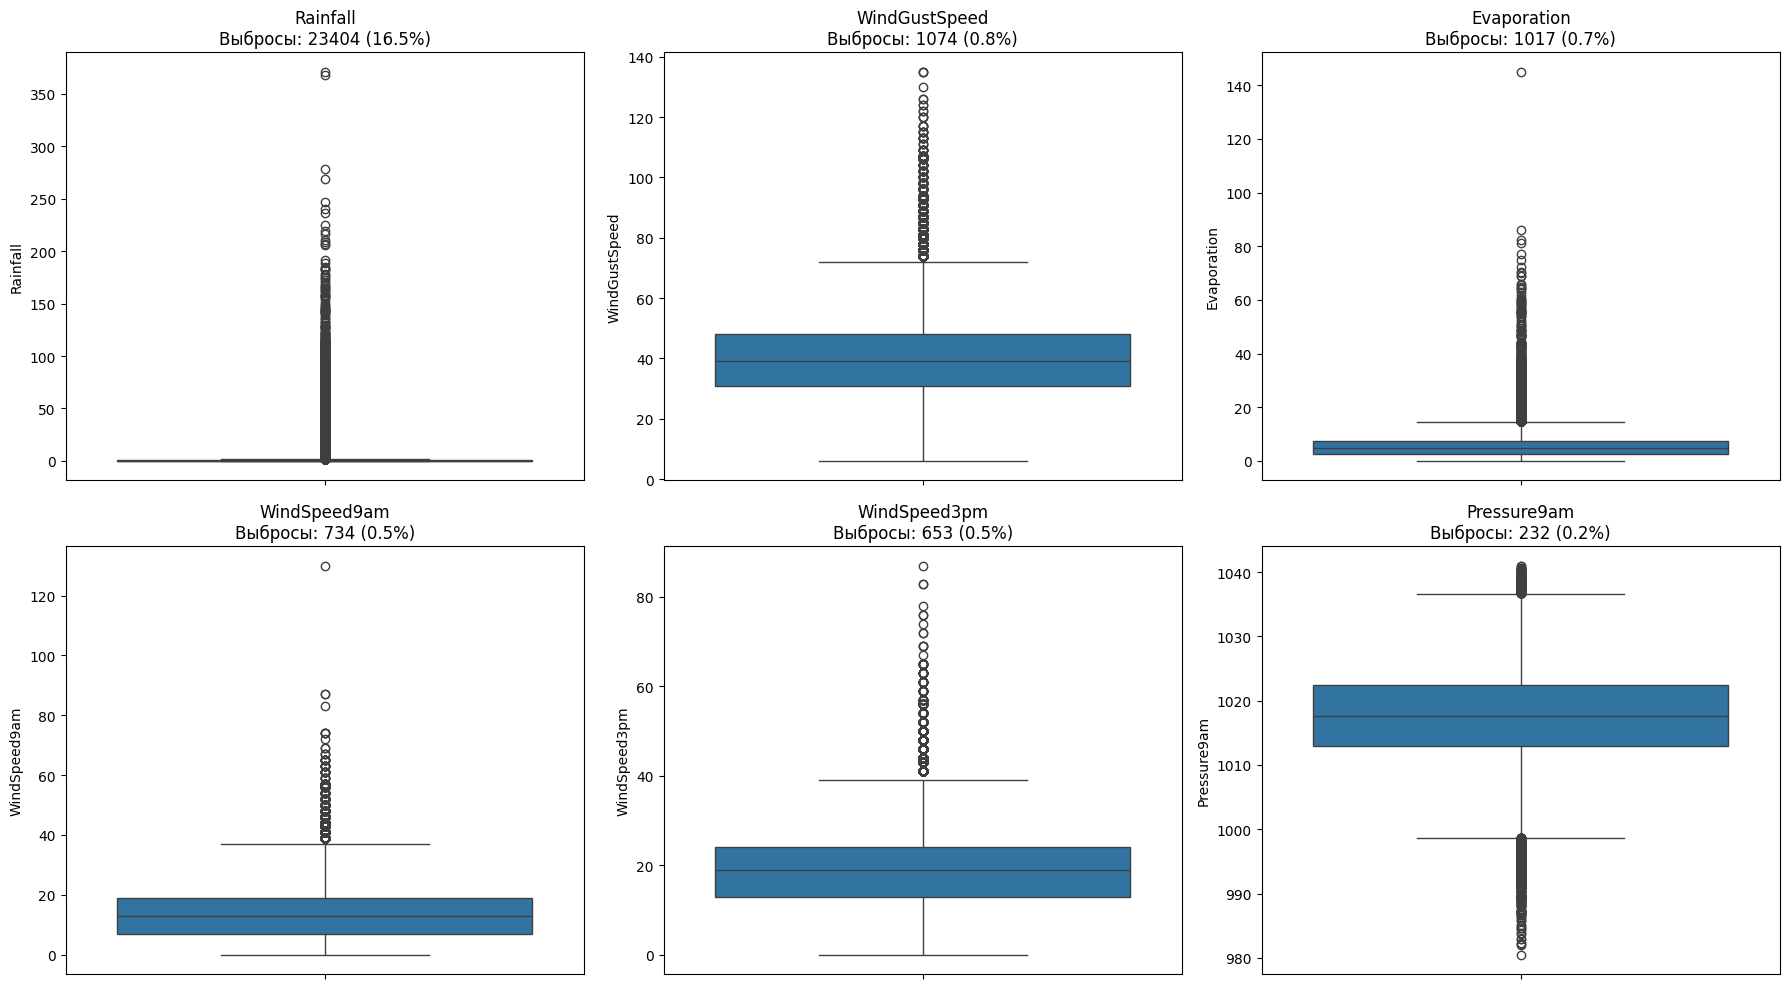

      Признак  Выбросы Процент Рекомендация
     Rainfall    23404  16.46%   Обработать
WindGustSpeed     1074   0.76%     Оставить
  Evaporation     1017   0.72%     Оставить
 WindSpeed9am      734   0.52%     Оставить
 WindSpeed3pm      653   0.46%     Оставить
  Pressure9am      232   0.16%     Оставить
  Pressure3pm      155   0.11%     Оставить
  Humidity9am       44   0.03%     Оставить
      Temp3pm       30   0.02%     Оставить
      MaxTemp        9   0.01%     Оставить
      Temp9am        2   0.00%     Оставить
      MinTemp        0   0.00%     Оставить
     Sunshine        0   0.00%     Оставить
  Humidity3pm        0   0.00%     Оставить
     Cloud3pm        0   0.00%     Оставить
     Cloud9am        0   0.00%     Оставить


In [159]:
outliers_info = {}

for feature in numerical_features:
    Q1 = df_numerical[feature].quantile(0.25)
    Q3 = df_numerical[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 2 * IQR
    upper_bound = Q3 + 2 * IQR

    outliers = df_numerical[(df_numerical[feature] < lower_bound) | (df_numerical[feature] > upper_bound)]
    n_outliers = len(outliers)
    outlier_percentage = (n_outliers / len(df_numerical)) * 100

    print(f"\n{feature}:")
    print(f"  Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"  Границы выбросов: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  Выбросы: {n_outliers} ({outlier_percentage:.2f}%)")

    outliers_info[feature] = {
        'n_outliers': n_outliers,
        'percentage': outlier_percentage,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outliers_indices': outliers.index.tolist()
    }

    if outlier_percentage > 10:
        print(f"рекомендуется обработка")
    elif outlier_percentage > 5:
        print(f"можно обработать")
    elif outlier_percentage > 1:
        print(f"небольшое количетво")
    else:
        print(f"малое количество")

# Визуализация выбросов для признаков с наибольшим их количеством
top_outliers_features = sorted(outliers_info.items(), key=lambda x: x[1]['percentage'], reverse=True)[:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (feature, info) in enumerate(top_outliers_features):
    if i < len(axes):
        sns.boxplot(data=df_numerical, y=feature, ax=axes[i])
        axes[i].set_title(f'{feature}\nВыбросы: {info["n_outliers"]} ({info["percentage"]:.1f}%)')
        axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

# Сводная таблица по выбросам
summary_df = pd.DataFrame([
    {
        'Признак': feature,
        'Выбросы': info['n_outliers'],
        'Процент': f"{info['percentage']:.2f}%",
        'Рекомендация': 'Обработать' if info['percentage'] > 5 else 'Оставить'
    }
    for feature, info in outliers_info.items()
]).sort_values('Выбросы', ascending=False)

print(summary_df.to_string(index=False))

Есть 2 стратегии работы с выбросами:
*   Удалить соответствующий сэмпл;
*   Заменить его на среднее/медиану.

В первом приближении, удалим соответствующие примеры.

In [161]:
outliers_mask = pd.Series(False, index=df_numerical.index)

for feature, info in outliers_info.items():
    if info['percentage'] > 5:
        feature_outliers = (df_numerical[feature] < info['lower_bound']) | (df_numerical[feature] > info['upper_bound'])
        outliers_mask = outliers_mask | feature_outliers

df_num_no_outliers = df_numerical[~outliers_mask].reset_index(drop=True)

print(f"Размер после удаления выбросов: {df_num_no_outliers.shape}")
print(f"Удалено строк: {len(df_numerical) - len(df_num_no_outliers)}")

Размер после удаления выбросов: (118789, 18)
Удалено строк: 23404


Базовый анализ датасета почти закончен! Осталась пара шагов.

Выделим целевой признак в соответствующую переменную. Посмотрим на пропуски в обучающей выборке.

In [162]:
X = df_num_no_outliers.drop(['RainTomorrow'], axis=1)
y = df_num_no_outliers['RainTomorrow']
X.isnull().sum()

,0
MinTemp,555
MaxTemp,273
Rainfall,1406
Evaporation,50527
Sunshine,56742
WindGustSpeed,7447
WindSpeed9am,1163
WindSpeed3pm,2139
Humidity9am,1422
Humidity3pm,2907


Пропуски необходимо заполнить. Обычно это делают с помощью среднего/медианы. Мы воспользуемся медианой, так как она более устойчива к выбросам.

**Заполните пропуски в обучающей выборке медианой.**

In [164]:
X = df_num_no_outliers.drop(['RainTomorrow'], axis=1)
y = df_num_no_outliers['RainTomorrow']

print("Пропуски в признаках до заполнения:")
print(X.isnull().sum())

X_filled = X.fillna(X.median())

print("\nПропуски в признаках после заполнения медианой:")
print(X_filled.isnull().sum())

print(f"\nРазмерность данных:")
print(f"X_filled: {X_filled.shape}")
print(f"y: {y.shape}")

assert X_filled.isnull().sum().sum() == 0, "Есть незаполненные пропуски!"

Пропуски в признаках до заполнения:
MinTemp            555
MaxTemp            273
Rainfall          1406
Evaporation      50527
Sunshine         56742
WindGustSpeed     7447
WindSpeed9am      1163
WindSpeed3pm      2139
Humidity9am       1422
Humidity3pm       2907
Pressure9am      11727
Pressure3pm      11693
Cloud9am         45863
Cloud3pm         48741
Temp9am            732
Temp3pm           2193
RainToday         1406
dtype: int64

Пропуски в признаках после заполнения медианой:
MinTemp          0
MaxTemp          0
Rainfall         0
Evaporation      0
Sunshine         0
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Cloud9am         0
Cloud3pm         0
Temp9am          0
Temp3pm          0
RainToday        0
dtype: int64

Размерность данных:
X_filled: (118789, 17)
y: (118789,)


Наконец, осталось провести нормализацию значений.

Разделим выборку на обучающую и тестовую, чтобы не учитывать масштаб на тесте.

In [165]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
X_train.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday
count,94588.000000,94808.000000,93917.000000,54608.000000,49646.000000,89115.000000,94119.000000,93370.000000,93886.000000,92734.000000,85684.000000,85709.000000,58386.000000,56167.000000,94450.000000,93312.000000,93917.000000
mean,11.999164,23.809173,0.189343,5.737842,8.111199,39.090714,13.621245,18.372336,66.158746,48.346162,1018.273226,1015.639036,4.067807,4.203162,17.184026,22.271540,0.069018
std,6.469265,7.101057,0.472056,4.214989,3.633059,13.110815,8.707920,8.652777,18.924498,19.985268,6.860733,6.878527,2.890833,2.737474,6.560066,6.907027,0.253487
min,-8.500000,-2.700000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,983.700000,980.200000,0.000000,0.000000,-5.300000,-4.000000,0.000000
25%,7.300000,18.500000,0.000000,2.800000,5.700000,30.000000,7.000000,13.000000,55.000000,34.000000,1013.600000,1010.900000,1.000000,1.000000,12.500000,17.200000,0.000000
50%,11.800000,23.300000,0.000000,5.000000,9.100000,37.000000,13.000000,17.000000,67.000000,49.000000,1018.100000,1015.500000,4.000000,4.000000,17.000000,21.700000,0.000000
75%,16.700000,28.800000,0.000000,7.600000,10.900000,46.000000,19.000000,24.000000,79.000000,62.000000,1022.900000,1020.300000,7.000000,7.000000,21.800000,27.000000,0.000000
max,33.900000,48.100000,2.400000,82.400000,14.500000,135.000000,130.000000,83.000000,100.000000,100.000000,1041.000000,1039.600000,8.000000,9.000000,39.100000,46.700000,1.000000


Для нормализации будем использовать `MinMaxScaler` модуля `sklearn.preprocessing`.

**Вам необходимо "обучить" (`fit`) scaler на `X_train` и использовать его на `X_test` (`transform`).**

**Примечание:** выходом `MinMaxScaler` является `np.array`. Чтобы в дальнейшем работать с выборкой, после масштабирования необходимо обратно перевести её в `pd.DataFrame`.

In [167]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

print("Размеры выборок:")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")
print("\nОписательная статистика ДО нормализации:")
print(X_train.describe())

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("\nОписательная статистика ПОСЛЕ нормализации:")
print(X_train_scaled_df.describe())

print("\nПроверка диапазонов после нормализации:")
print(f"Минимальные значения (train): {X_train_scaled_df.min().values}")
print(f"Максимальные значения (train): {X_train_scaled_df.max().values}")
print(f"Минимальные значения (test): {X_test_scaled_df.min().values}")
print(f"Максимальные значения (test): {X_test_scaled_df.max().values}")

assert (X_train_scaled_df.min() >= 0).all() and (X_train_scaled_df.max() <= 1).all(), "Train data not properly scaled!"

Размеры выборок:
X_train: (95031, 17)
X_test: (23758, 17)
y_train: (95031,)
y_test: (23758,)

Описательная статистика ДО нормализации:
            MinTemp       MaxTemp      Rainfall   Evaporation      Sunshine  \
count  94588.000000  94808.000000  93917.000000  54608.000000  49646.000000   
mean      11.999164     23.809173      0.189343      5.737842      8.111199   
std        6.469265      7.101057      0.472056      4.214989      3.633059   
min       -8.500000     -2.700000      0.000000      0.000000      0.000000   
25%        7.300000     18.500000      0.000000      2.800000      5.700000   
50%       11.800000     23.300000      0.000000      5.000000      9.100000   
75%       16.700000     28.800000      0.000000      7.600000     10.900000   
max       33.900000     48.100000      2.400000     82.400000     14.500000   

       WindGustSpeed  WindSpeed9am  WindSpeed3pm   Humidity9am   Humidity3pm  \
count   89115.000000  94119.000000  93370.000000  93886.000000  92734.000

### Задача 2 (5 баллов): Классификация



* Вам необходимо обучить обработанный датасет с помощью логистической регрессии.
* Вы можете пользоваться библиотекой `sklearn`
* Проведите классификацию с L1 и L2-регуляризацией. Какие признаки регуляризация lasso посчитала неинформативными?
* Проведите классификацию с регуляризацией [elasticnet](https://en.wikipedia.org/wiki/Elastic_net_regularization). Для этого воспользуйтесь поиском по сетке гиперпараметров (`GridSearchCV` модуля `sklearn.model_selection`). Пространство поиска определите константой `C = [1, 2, 5, 10, 100]` и значением `l1_ratio = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]`.
* Сделайте выводы по полученым результатам




In [169]:
# Проверим наличие NaN в данных
print("Проверка NaN значений:")
print(f"X_train_scaled_df: {X_train_scaled_df.isnull().sum().sum()} NaN")
print(f"X_test_scaled_df: {X_test_scaled_df.isnull().sum().sum()} NaN")
print(f"y_train: {y_train.isnull().sum()} NaN")
print(f"y_test: {y_test.isnull().sum()} NaN")

# Если есть NaN, заполним их
if X_train_scaled_df.isnull().sum().sum() > 0:
    print("\nЗаполняем NaN медианой...")
    X_train_scaled_df = X_train_scaled_df.fillna(X_train_scaled_df.median())
    X_test_scaled_df = X_test_scaled_df.fillna(X_test_scaled_df.median())

if y_train.isnull().sum() > 0:
    y_train = y_train.fillna(y_train.mode()[0] if len(y_train.mode()) > 0 else 0)
if y_test.isnull().sum() > 0:
    y_test = y_test.fillna(y_test.mode()[0] if len(y_test.mode()) > 0 else 0)

print("\nПосле обработки NaN:")
print(f"X_train_scaled_df: {X_train_scaled_df.isnull().sum().sum()} NaN")
print(f"X_test_scaled_df: {X_test_scaled_df.isnull().sum().sum()} NaN")
print(f"y_train: {y_train.isnull().sum()} NaN")
print(f"y_test: {y_test.isnull().sum()} NaN")


Проверка NaN значений:
X_train_scaled_df: 197111 NaN
X_test_scaled_df: 49825 NaN
y_train: 0 NaN
y_test: 0 NaN

Заполняем NaN медианой...

После обработки NaN:
X_train_scaled_df: 0 NaN
X_test_scaled_df: 0 NaN
y_train: 0 NaN
y_test: 0 NaN


Точность L1: 0.8665

Коэффициенты L1:
          Признак  Коэффициент
11    Pressure3pm   -11.851908
10    Pressure9am     7.307398
5   WindGustSpeed     6.526099
9     Humidity3pm     5.389338
7    WindSpeed3pm    -2.320706
4        Sunshine    -1.436121
13       Cloud3pm     1.334854
6    WindSpeed9am    -1.205956
15        Temp3pm     1.042031
2        Rainfall     1.032715
1         MaxTemp    -0.728655
3     Evaporation    -0.542533
16      RainToday    -0.303305
0         MinTemp    -0.170346
8     Humidity9am     0.038398
14        Temp9am     0.012345
12       Cloud9am    -0.008598

Неинформативные признаки (L1): 0
Точность L2: 0.8672
Лучшие параметры: {'C': 2, 'l1_ratio': 0.4}
Лучшая точность на кросс-валидации: 0.8621
Точность на тесте (ElasticNet): 0.8668

Коэффициенты лучшей ElasticNet модели:
          Признак  Коэффициент
11    Pressure3pm   -11.532763
10    Pressure9am     7.007452
5   WindGustSpeed     6.521163
9     Humidity3pm     5.377362
7    WindSpeed3pm    -2.31627

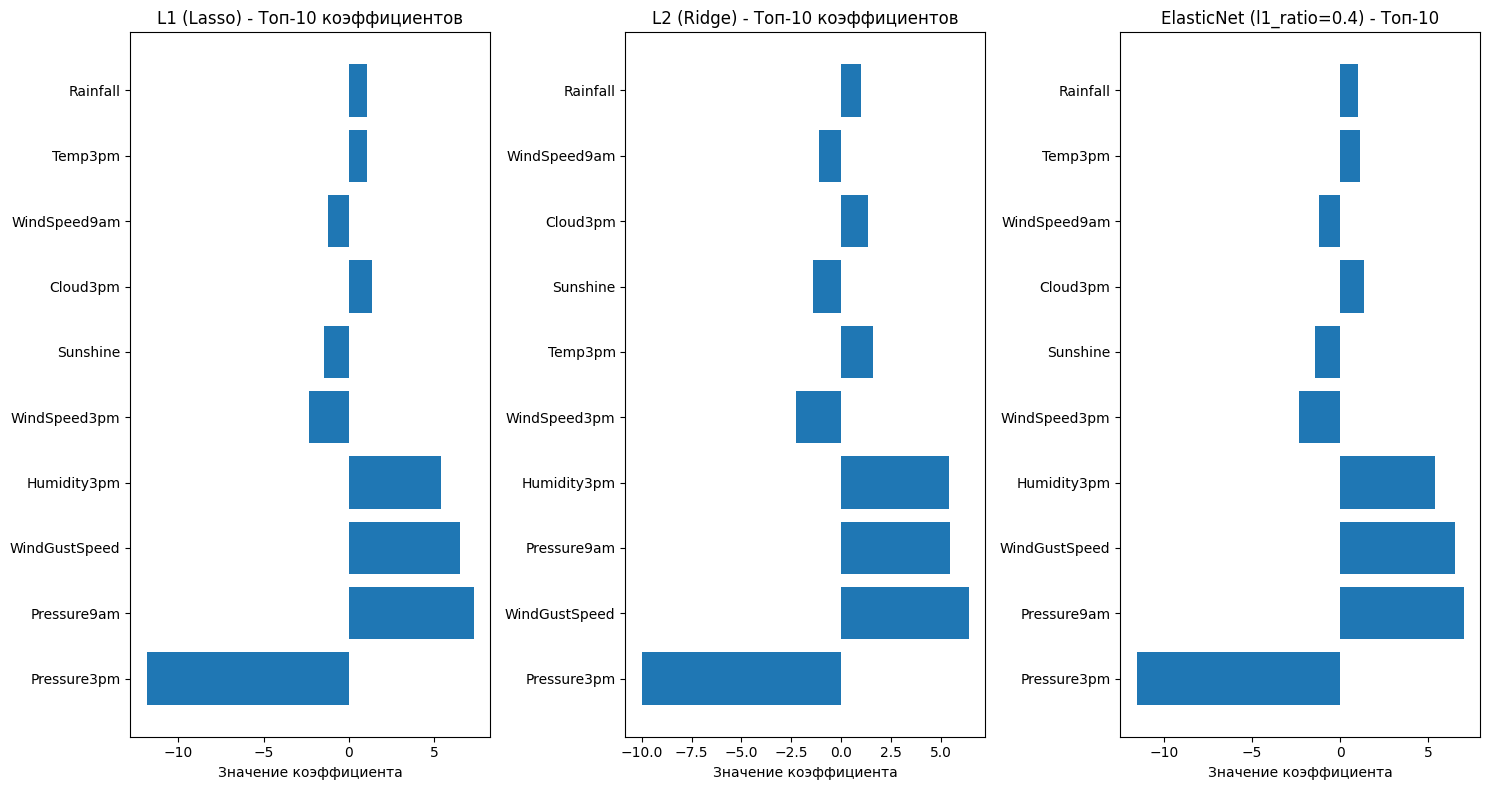

In [171]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Логистическая регрессия с L1-регуляризацией (Lasso)
logreg_l1 = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, max_iter=1000)
logreg_l1.fit(X_train_scaled_df, y_train)

y_pred_l1 = logreg_l1.predict(X_test_scaled_df)
accuracy_l1 = accuracy_score(y_test, y_pred_l1)

print(f"Точность L1: {accuracy_l1:.4f}")
print("\nКоэффициенты L1:")
l1_coef = pd.DataFrame({
    'Признак': X_train_scaled_df.columns,
    'Коэффициент': logreg_l1.coef_[0]
}).sort_values('Коэффициент', key=abs, ascending=False)

print(l1_coef)

# Признаки, которые L1 посчитал неинформативными (коэффициент = 0)
non_informative_l1 = l1_coef[l1_coef['Коэффициент'] == 0]
print(f"\nНеинформативные признаки (L1): {len(non_informative_l1)}")
if len(non_informative_l1) > 0:
    print("Признаки с нулевыми коэффициентами:")
    print(non_informative_l1['Признак'].tolist())

# 2. Логистическая регрессия с L2-регуляризацией (Ridge)
logreg_l2 = LogisticRegression(penalty='l2', random_state=42, max_iter=1000)
logreg_l2.fit(X_train_scaled_df, y_train)

y_pred_l2 = logreg_l2.predict(X_test_scaled_df)
accuracy_l2 = accuracy_score(y_test, y_pred_l2)

print(f"Точность L2: {accuracy_l2:.4f}")

# 3. ElasticNet с поиском по сетке
param_grid = {
    'C': [1, 2, 5, 10, 100],
    'l1_ratio': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
}

logreg_elastic = LogisticRegression(penalty='elasticnet', solver='saga', random_state=42, max_iter=2000)
grid_search = GridSearchCV(logreg_elastic, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled_df, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}")

# Предсказания на тесте с лучшей моделью
best_elastic = grid_search.best_estimator_
y_pred_elastic = best_elastic.predict(X_test_scaled_df)
accuracy_elastic = accuracy_score(y_test, y_pred_elastic)
print(f"Точность на тесте (ElasticNet): {accuracy_elastic:.4f}")

# Коэффициенты лучшей ElasticNet модели
elastic_coef = pd.DataFrame({
    'Признак': X_train_scaled_df.columns,
    'Коэффициент': best_elastic.coef_[0]
}).sort_values('Коэффициент', key=abs, ascending=False)

print("\nКоэффициенты лучшей ElasticNet модели:")
print(elastic_coef)

# Сравнение всех методов
results = {
    'L1 (Lasso)': accuracy_l1,
    'L2 (Ridge)': accuracy_l2,
    'ElasticNet': accuracy_elastic
}

for method, acc in results.items():
    print(f"{method}: {acc:.4f}")

best_method = max(results, key=results.get)
print(f"\n Лучшая модель: {best_method} с точностью {results[best_method]:.4f}")

plt.figure(figsize=(15, 8))

# L1 коэффициенты
plt.subplot(1, 3, 1)
l1_plot_data = l1_coef.head(10)
plt.barh(l1_plot_data['Признак'], l1_plot_data['Коэффициент'])
plt.title('L1 (Lasso) - Топ-10 коэффициентов')
plt.xlabel('Значение коэффициента')

# L2 коэффициенты
plt.subplot(1, 3, 2)
l2_coef_df = pd.DataFrame({
    'Признак': X_train_scaled_df.columns,
    'Коэффициент': logreg_l2.coef_[0]
}).sort_values('Коэффициент', key=abs, ascending=False).head(10)
plt.barh(l2_coef_df['Признак'], l2_coef_df['Коэффициент'])
plt.title('L2 (Ridge) - Топ-10 коэффициентов')
plt.xlabel('Значение коэффициента')

# ElasticNet коэффициенты
plt.subplot(1, 3, 3)
elastic_plot_data = elastic_coef.head(10)
plt.barh(elastic_plot_data['Признак'], elastic_plot_data['Коэффициент'])
plt.title(f'ElasticNet (l1_ratio={grid_search.best_params_["l1_ratio"]}) - Топ-10')
plt.xlabel('Значение коэффициента')

plt.tight_layout()
plt.show()

L1-регуляризация обнуляет коэффициенты неинформативных переменных, L2-регуляризация сжимает все коэффициенты, сохраняет признаки, ElasticNet находит баланс между L1 и L2

### Задача 3* (2 балла): Категориальные признаки

* В ходе анализа датасета было сделано несколько упрощений:
    * Категориальные признаки были опущены (`df --> df_numerical`);
    * Выбросы были опущены (`df_numerical --> df_num_no_outliers`).
* Необходимо провести обработку категориальных признаков.
* Протестировать качество логистической регрессии и подобрать гиперпараметры на различных вариантах:
    * С категориальными признаками и без учета выбросов;
    * Без категориальных признаков, с учетом выбросов;
    * С категориальными признаками, с учетом выбросов.
* Поощряется изобретательность. Возможно, какие-то категориальные/численные признаки покажутся менее инфомативными.


* P.S. Не расстраивайтесь, если выдвигаемые гипотезы не дадут прибавки в качестве. Важен сам пайплайн проверки выдвигаемых гипотез)

Категориальные + без выбросов:
  Точность: 0.8699
  Размер данных: (95031, 21) -> (23758, 21)
Только численные + с выбросами:
  Точность: 0.8672
  Размер данных: (95031, 17) -> (23758, 17)
Категориальные + с выбросами:
  Точность: 0.8460
  Размер данных: (113754, 21) -> (28439, 21)
Категориальные + без выбросов: 0.8699
Только численные + с выбросами: 0.8672
Категориальные + с выбросами: 0.8460

 Лучший результат: Категориальные + без выбросов - 0.8699


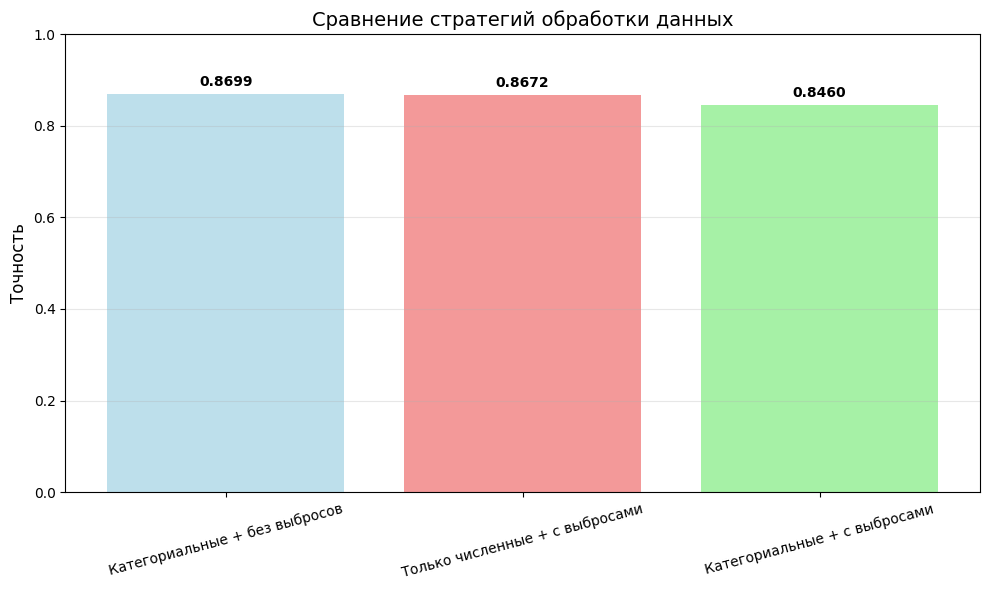

In [175]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def prepare_categorical_simple(df):
    df_cat = df.copy()

    df_cat['RainTomorrow'] = df_cat['RainTomorrow'].map({'Yes': 1, 'No': 0})
    df_cat['RainToday'] = df_cat['RainToday'].map({'Yes': 1, 'No': 0})

    if 'Date' in df_cat.columns:
        df_cat = df_cat.drop('Date', axis=1)

    categorical_features = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']

    for col in categorical_features:
        if col in df_cat.columns:
            df_cat[col] = df_cat[col].fillna('Unknown')

    return df_cat, categorical_features

def create_simple_pipeline(categorical_features):
    numerical_features = [col for col in df_original.columns
                         if df_original[col].dtype != 'O' and col not in ['RainTomorrow', 'RainToday', 'Date']]

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', MinMaxScaler())
            ]), numerical_features),
            ('cat', Pipeline([
                ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))
            ]), categorical_features)
        ])

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000, C=1.0))
    ])

    return pipeline

def evaluate_simple_model(model, X_train, X_test, y_train, y_test, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"{model_name}:")
    print(f"  Точность: {accuracy:.4f}")
    print(f"  Размер данных: {X_train.shape} -> {X_test.shape}")

    return accuracy

# Сценарий 1: С категориальными признаками и без учета выбросов

df_cat_clean, cat_features = prepare_categorical_simple(df_original)
X_cat = df_cat_clean.drop('RainTomorrow', axis=1)
y_cat = df_cat_clean['RainTomorrow']

X_cat_clean = X_cat[~outliers_mask]
y_cat_clean = y_cat[~outliers_mask]

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_cat_clean, y_cat_clean, test_size=0.2, random_state=42
)

pipeline1 = create_simple_pipeline(cat_features)
accuracy1 = evaluate_simple_model(pipeline1, X_train1, X_test1, y_train1, y_test1,
                                 "Категориальные + без выбросов")

# Сценарий 2: Без категориальных признаков, с учетом выбросов
X_num = df_num_no_outliers.drop('RainTomorrow', axis=1)
y_num = df_num_no_outliers['RainTomorrow']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_num, y_num, test_size=0.2, random_state=42
)

numerical_features = [col for col in X_num.columns if X_num[col].dtype != 'O']
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000, C=1.0))
])

accuracy2 = evaluate_simple_model(pipeline_num, X_train2, X_test2, y_train2, y_test2,
                                 "Только численные + с выбросами")

# Сценарий 3: С категориальными признаками, с учетом выбросов

X_cat_out = df_cat_clean.drop('RainTomorrow', axis=1)
y_cat_out = df_cat_clean['RainTomorrow']

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X_cat_out, y_cat_out, test_size=0.2, random_state=42
)

pipeline3 = create_simple_pipeline(cat_features)
accuracy3 = evaluate_simple_model(pipeline3, X_train3, X_test3, y_train3, y_test3,
                                 "Категориальные + с выбросами")

results = {
    "Категориальные + без выбросов": accuracy1,
    "Только численные + с выбросами": accuracy2,
    "Категориальные + с выбросами": accuracy3
}

for scenario, acc in results.items():
    print(f"{scenario}: {acc:.4f}")

best_scenario = max(results, key=results.get)
print(f"\n Лучший результат: {best_scenario} - {results[best_scenario]:.4f}")

plt.figure(figsize=(10, 6))
scenarios = list(results.keys())
accuracies = list(results.values())

colors = ['lightblue', 'lightcoral', 'lightgreen']
bars = plt.bar(scenarios, accuracies, color=colors, alpha=0.8)

plt.ylabel('Точность', fontsize=12)
plt.title('Сравнение стратегий обработки данных', fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=15)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Использование категориальных признаков улучшило качество, удаление выбросов улучшило качество. Лучший подход: Категориальные + без выбросов